# 07 — Neural Local Volatility: correctness-revised GPU ablations

## Research question and frozen development protocol

This notebook completes the **GPU-internal Neural-LV search** before any cross-model universe is
redesigned. It asks whether a time-realistic GTX 1660 Ti calibration improves conditional next-day
option repricing and one-day hedging over the CPU Neural-LV lineage. March 1–8, 2024 is frozen as
development: the contract filter, next-day join, OTM-on-both-dates population, pooled price metrics,
hedge accounting, evaluation seeds and 50,000-path evaluation budget are identical for every
ablation. March 8–28 remains observed and is not described as an untouched test.

The forward-normalised model is
$$
X_t=S_t/F_d(t),\qquad dX_t=X_t\sigma_{\theta,d}(t,X_t)\,dW_t.
$$
When rolling from date $d_0$ to $d_1=d_0+e$, the correct old state corresponding to a new state
$x$ is
$$
x_{\rm old}=x\frac{F_{d_1}(u)}{F_{d_0}(u+e)}.
$$
That transformation is now used by a curve-aware teacher. Because its multiplier varies with time,
it cannot in general be absorbed exactly into the first affine layer; the new same-shaped network is
therefore initialized by a short deterministic functional distillation. Temporal regularisation, when
enabled, targets this same old volatility **function on a fixed time/state probe grid**, not old
parameters. Optional CV transfer uses the corresponding state transformation as well.

## Default model and computational budget

- Completed CPU March-1 coefficient checkpoint; only its CV hedge is fitted on the anchor date.
- Shared 4×50 trunk with maturity heads; MSE; 8,192 paths; 400 contracts.
- Fifteen paired updates per rolling date, each with 10 SDE and 10 CV steps.
- Learned 3×30 control-variate networks; tamed Euler; 96 steps/year plus exact maturities.
- Uniform contract sampling, surrogate tamed gradient and constant learning rate.
- Fixed update 15 for `gpu_reference_8k`; bounded selection compares 0/5/10/15 using date-$t$
  information only. Tomorrow's quotes never select that day's checkpoint.
- 50,000 development paths, 100,000 confirmation paths and a quarantined optional 400,000 audit.

The routine hedge table is deliberately explicit:

1. `learned_cv`: the Sabaté-style learned martingale integrand, in share-delta units;
2. `frozen_physical`: common-shock state bump of the frozen local-volatility function;
3. `sticky_normalised`: the historical re-centred-distribution heuristic;
4. `optionmetrics`: the matched market delta.

The learned CV hedge is the default model-native headline, while frozen physical remains a
co-primary diagnostic. Sticky normalised is retained but is not called the frozen-model delta.
Every convention uses the same overnight self-financing accounting and is exported separately.

## Ablations and execution order

Edit only `SELECTED`. Run one factor at a time; do not launch the Cartesian product. The named
choices cover 4k/8k/16k paths, bounded selection, CV transfer, temporal regularisation, Huber,
two-batch loss, maturity sampling, exact gradient, independent interval networks, 192 steps/year,
log Euler, an LR schedule and a **budget-matched Sabaté proxy**. The proxy uses independent
interval networks and Sabaté-like learning-rate choices but is not the infeasible 40k-path,
approximately 1000-epoch paper experiment.

Recommended order:

1. Run every cell with `RUN_MODE='smoke'` and inspect the audits.
2. Set `RUN_MODE='development'`, `SELECTED=['gpu_reference_8k']`, and run the corrected reference.
3. Run one-factor ablations under the unchanged protocol.
4. Confirm only Pareto finalists with several independent `CONFIRMATION_SEEDS`.
5. Freeze the chosen NLV specification; build the common BS/LV/Heston/NLV benchmark afterwards.

## Inputs, persistence and the completed old 4k run

Put the four SPX CSVs beside the notebook or edit `DATA_ROOT`. Set `CPU_INITIAL_CHECKPOINT` to
`initial_full_otm_refinement_20240301.pt`. Research modes refuse to cold-start or fall back to CPU.
Each cache is keyed by critical executable code, raw data, the frozen protocol population, complete
configuration, CPU checkpoint and seed. Resume files restore coefficient and CV weights, both
optimisers, sampler state, all RNG states, update count, monitoring history and candidates.

The already completed **pre-correction** 4k run (OTM next-day price RMSE 4.4053, historical sticky
hedge RMSE 2.0837, OptionMetrics 1.8842; about 2.32 hours) is useful diagnostic evidence only. It
used the old state transfer and old carry formula, so this notebook never imports it as a corrected
ablation result and writes to a new cache namespace.

Expensive cells are anchor-CV fitting, rolling training, reranking, physical-delta bumps and final
confirmation. Progress bars are limited to configuration/seed, date, paired update, reranking,
evaluation chunks and delta bumps. Numerical files are saved before plotting in an isolated process.


In [24]:
from pathlib import Path
from dataclasses import dataclass, asdict, replace
from datetime import datetime
import copy, gc, hashlib, inspect, json, marshal, math, os, platform, random, sys, time, warnings
import subprocess, importlib.metadata

DATA_ROOT = Path.cwd()
DATA_NAMES = {
    'options': 'one_month_spx_option_price.csv',
    'forwards': 'one_month_spx_forward_price.csv',
    'spot': 'one_month_spx_security_price.csv',
    'rates': 'one_month_spx_zero_coupon_yield_curve.csv',
}
CACHE_ROOT = Path('neural_lv_gpu_correctness_revision_cache')
CPU_INITIAL_CHECKPOINT = Path(
    'neural_lv_cpu_final_edited_cache/initial_calibration/'
    'initial_full_otm_refinement_20240301.pt'
)

# Safe first execution. Research runs require CUDA and the CPU anchor.
RUN_MODE = 'development'  # smoke | development | benchmark | fresh_test
ALLOW_CPU = False   # set True only in smoke mode for engineering validation
SHOW_PROGRESS = True
SELECTED = ['gpu_reference_8k']
CONFIRMATION_SEEDS = [12345]  # finalists: [12345, 22345, 32345]

INITIAL_DATE = '2024-03-01'
DEVELOPMENT_END = '2024-03-08'
BENCHMARK_END = '2024-03-28'
FRESH_TEST_START = None
FRESH_TEST_END = None
FROZEN_CONFIG = 'gpu_reference_8k'

PRIMARY_POPULATION = 'otm_on_both_dates'
HEDGE_CONVENTIONS = ('learned_cv', 'frozen_physical', 'sticky_normalised', 'optionmetrics')
EVALUATION_SHOCK_STEPS = 384  # common fine Brownian grid, aggregated to each evaluation grid

# Optional later common-universe exports. They are not needed for the GPU-only search.
BASELINE_CONTRACT_FILES = {}

RUN_DELTA_STABILITY_AUDIT = False
DELTA_AUDIT_DATE = INITIAL_DATE
DELTA_AUDIT_PATHS = 50_000


@dataclass(frozen=True)
class Experiment:
    architecture: str = 'shared'       # shared | independent
    loss: str = 'mse'                  # mse | huber | two_batch
    paths: int = 8192
    micro_paths: int = 512
    contracts: int = 400
    steps_per_phase: int = 10          # 10 SDE + 10 CV steps per paired update
    updates: int = 15
    anchor_cv_updates: int = 15        # coefficient stays equal to the imported CPU anchor
    sde_lr: float = 1e-4
    cv_lr: float = 1e-3
    sde_lr_milestones: tuple[int, ...] = ()
    sde_lr_gamma: float = 1.0
    sampler: str = 'uniform'           # uniform | maturity_random
    weighting: str = 'contracts'       # contracts | maturities
    selection: str = 'fixed'           # fixed | bounded | early_stop
    candidate_updates: tuple[int, ...] = (0, 5, 10, 15)
    patience_events: int = 4           # failed monitoring occasions, never optimiser steps
    min_updates: int = 15
    monitor_every: int = 5
    monitor_paths: int = 8192
    rerank_paths: int = 50_000
    monitor_repeats: int = 2
    top_k: int = 5
    min_improvement: float = 0.02
    huber_delta: float = 3.0
    temporal_lambda: float = 0.0
    cv_warm_start: bool = False
    scheme: str = 'tamed'              # tamed | log_euler
    gradient: str = 'surrogate'        # surrogate | exact
    steps_per_year: int = 96
    transfer_distill_steps: int = 40
    transfer_distill_lr: float = 5e-4
    transfer_probe_x: int = 41
    transfer_probe_times: int = 3
    cv_transfer_distill_steps: int = 5
    cv_transfer_contract_cap: int = 256
    routine_delta_bumps: tuple[int, ...] = (5,)
    eval_paths: int = 50_000
    final_paths: int = 100_000
    audit_paths: int = 400_000
    eval_chunk: int = 2000


BASE = Experiment()
CONFIGS = {
    'gpu_reference_8k': BASE,
    'gpu_reference_4k': replace(BASE, paths=4096),
    'bounded_selection': replace(BASE, selection='bounded'),
    'cv_transfer': replace(BASE, cv_warm_start=True),
    'temporal': replace(BASE, temporal_lambda=0.01),
    'huber3': replace(BASE, loss='huber'),
    'two_batch': replace(BASE, loss='two_batch'),
    'random_maturity': replace(BASE, sampler='maturity_random'),
    'exact_gradient': replace(BASE, gradient='exact'),
    'independent_architecture': replace(BASE, architecture='independent'),
    'grid192': replace(BASE, steps_per_year=192),
    'log_euler': replace(BASE, scheme='log_euler', gradient='exact'),
    'paths16k': replace(BASE, paths=16384),
    'scheduled_lr': replace(BASE, sde_lr_milestones=(5, 10), sde_lr_gamma=0.5),
    'sabate_budget_matched': replace(
        BASE, architecture='independent', sde_lr=1e-3,
        sde_lr_milestones=(8, 12), sde_lr_gamma=0.2,
    ),
    'longer_patience': replace(
        BASE, selection='early_stop', updates=60, candidate_updates=(0,),
        min_updates=15, monitor_every=5, patience_events=4,
    ),
    'final_audit_400k': replace(BASE, final_paths=400_000),
}


def validate_config(c):
    choices = {
        'architecture': {'shared', 'independent'},
        'loss': {'mse', 'huber', 'two_batch'},
        'sampler': {'uniform', 'maturity_random'},
        'weighting': {'contracts', 'maturities'},
        'selection': {'fixed', 'bounded', 'early_stop'},
        'scheme': {'tamed', 'log_euler'},
        'gradient': {'surrogate', 'exact'},
    }
    for key, allowed in choices.items():
        if getattr(c, key) not in allowed:
            raise ValueError(f'{key}={getattr(c, key)!r}; expected one of {sorted(allowed)}')
    positive = (
        'paths', 'micro_paths', 'contracts', 'steps_per_phase', 'updates',
        'anchor_cv_updates', 'patience_events', 'min_updates', 'monitor_every',
        'monitor_paths', 'rerank_paths', 'monitor_repeats', 'top_k',
        'transfer_distill_steps', 'transfer_probe_x', 'transfer_probe_times',
        'cv_transfer_distill_steps', 'cv_transfer_contract_cap',
        'eval_paths', 'final_paths', 'audit_paths', 'eval_chunk', 'steps_per_year',
    )
    for key in positive:
        if getattr(c, key) <= 0:
            raise ValueError(f'{key} must be positive')
    for key in ('monitor_paths', 'rerank_paths', 'eval_paths', 'final_paths', 'audit_paths', 'eval_chunk'):
        if getattr(c, key) % 2:
            raise ValueError(f'{key} must be even for antithetic simulation')
    if min(c.sde_lr, c.cv_lr, c.huber_delta, c.sde_lr_gamma, c.transfer_distill_lr) <= 0:
        raise ValueError('Invalid learning rate or Huber threshold')
    if c.temporal_lambda < 0:
        raise ValueError('temporal_lambda cannot be negative')
    if 5 not in c.routine_delta_bumps or any(b <= 0 for b in c.routine_delta_bumps):
        raise ValueError('routine_delta_bumps must contain the 5 bp headline bump')
    if any(m <= 0 or m >= c.updates for m in c.sde_lr_milestones):
        raise ValueError('SDE LR milestones must lie strictly inside the update budget')
    if tuple(sorted(set(c.sde_lr_milestones))) != c.sde_lr_milestones:
        raise ValueError('SDE LR milestones must be unique and sorted')
    if c.selection == 'bounded':
        expected = (0, 5, 10, c.updates)
        if c.updates != 15 or c.candidate_updates != expected:
            raise ValueError(f'bounded selection requires candidate updates {expected}')
    if c.selection == 'early_stop' and c.min_updates > c.updates:
        raise ValueError('min_updates cannot exceed updates')
    if c.eval_paths != 50_000 and c != CONFIGS.get('final_audit_400k'):
        raise ValueError('GPU-development ablations must retain the fixed 50,000-path evaluation')


assert RUN_MODE in {'smoke', 'development', 'benchmark', 'fresh_test'}
if ALLOW_CPU and RUN_MODE != 'smoke':
    raise ValueError('ALLOW_CPU=True is permitted only in smoke mode')
for name, c in CONFIGS.items():
    validate_config(c)
if not SELECTED or any(k not in CONFIGS for k in SELECTED):
    raise ValueError('Unknown SELECTED configuration')
if FROZEN_CONFIG not in CONFIGS:
    raise ValueError('Unknown FROZEN_CONFIG')


In [25]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: c:\Users\pengl\anaconda3\envs\nlv-gpu\python.exe
PyTorch: 2.14.0+cu130
PyTorch CUDA build: 13.0
CUDA available: True
GPU count: 1
GPU: NVIDIA GeForce GTX 1660 Ti


## 1. Environment, precision and persistence

Research uses float32 simulation/weights and float64 statistical reductions. TF32 and mixed precision
are disabled for the equivalence baseline. No `KMP_DUPLICATE_LIB_OK` override is used. Plotting is
performed in a fresh process, avoiding the known CPU notebook OpenMP collision. CUDA speed and
memory must be measured on your RTX: this notebook does not claim a hardware-tested speedup.


In [26]:
for key in ('OMP_NUM_THREADS','MKL_NUM_THREADS','OPENBLAS_NUM_THREADS'):
    os.environ.setdefault(key,'2')
import numpy as np
import pandas as pd
from scipy.interpolate import PchipInterpolator
from scipy.optimize import brentq
from scipy.special import ndtr
from tqdm.auto import tqdm
import torch
import torch.nn as nn

if not torch.cuda.is_available() and not ALLOW_CPU:
    raise RuntimeError('CUDA unavailable. Select a CUDA-enabled environment; use ALLOW_CPU=True only for smoke testing.')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(2)
if DEVICE.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
SEED = int(CONFIRMATION_SEEDS[0])
INITIAL_DATE, DEVELOPMENT_END = pd.Timestamp(INITIAL_DATE), pd.Timestamp(DEVELOPMENT_END)
TEST_END = pd.Timestamp(BENCHMARK_END)
SDE_HIDDEN_LAYERS, SDE_WIDTH = 4, 50
HEDGE_HIDDEN_LAYERS, HEDGE_WIDTH = 3, 30
BASE_STEPS_PER_YEAR = 96
FINAL_MC_PATHS, FINAL_PATH_CHUNK = 100000, 2000
ROUTINE_DELTA_BUMP_BPS, DELTA_AUDIT_BUMP_BPS, DELTA_HEADLINE_BPS = (5,), (1,5,10), 5
CACHE_DIR = CACHE_ROOT
CACHE_ROOT.mkdir(parents=True,exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def cpu_state(module):
    return {k:v.detach().cpu().clone() for k,v in module.state_dict().items()}

def atomic_save(payload,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix(path.suffix+'.tmp'); torch.save(payload,tmp); os.replace(tmp,path)

def atomic_csv(frame,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix('.csv.tmp'); frame.to_csv(tmp,index=False); os.replace(tmp,path)

def stage_log(message):
    print(f'{datetime.now().isoformat(timespec="seconds")} | {message}',flush=True)

def digest_file(path):
    with open(path,'rb') as f: return hashlib.file_digest(f,'sha256').hexdigest()

environment = {'python':sys.version,'platform':platform.platform(),'torch':torch.__version__,
    'numpy':np.__version__,'pandas':pd.__version__,'cuda':torch.version.cuda,'device':str(DEVICE),
    'gpu':torch.cuda.get_device_name() if DEVICE.type=='cuda' else None,
    'vram_bytes':torch.cuda.get_device_properties(DEVICE).total_memory if DEVICE.type=='cuda' else None}
(CACHE_ROOT/'environment.json').write_text(json.dumps(environment,indent=2))
print(environment)
set_seed(SEED)


{'python': '3.13.15 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 17:17:48) [MSC v.1942 64 bit (AMD64)]', 'platform': 'Windows-11-10.0.26200-SP0', 'torch': '2.14.0+cu130', 'numpy': '2.3.4', 'pandas': '2.3.3', 'cuda': '13.0', 'device': 'cuda', 'gpu': 'NVIDIA GeForce GTX 1660 Ti', 'vram_bytes': 6442123264}


## 2. Data and market curves — same convention as CPU

Use original OptionMetrics columns and explicit filenames. Filtering, forward-normalisation,
AM/PM curves and the near-ATM tighter-spread choice are carried over from the CPU notebook.
The deterministic 80/20 split is a same-day interpolation diagnostic. Stage I in the historical
CPU lineage saw a capped subset of the full surface: its historical Stage-II holdout was not
guaranteed untouched by pretraining. This notebook's cold-start branch trains only on its 80% split.
An imported CPU anchor is labelled as imported; its fit is not advertised as a new held-out result.


In [27]:
DATA_FILES = {k: DATA_ROOT / v for k,v in DATA_NAMES.items()}
missing = [p.name for p in DATA_FILES.values() if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Place the four SPX CSV files beside this notebook. Missing: " + ", ".join(missing)
    )

options_raw = pd.read_csv(DATA_FILES["options"], low_memory=False)
forwards_raw = pd.read_csv(DATA_FILES["forwards"], low_memory=False)
spot_raw = pd.read_csv(DATA_FILES["spot"], low_memory=False)
rates_raw = pd.read_csv(DATA_FILES["rates"], low_memory=False)

def file_sha256(path):
    with open(path, "rb") as f:
        return hashlib.file_digest(f, "sha256").hexdigest()

manifest = {
    k: {"file": p.name, "bytes": p.stat().st_size, "sha256": file_sha256(p)}
    for k, p in DATA_FILES.items()
}
(CACHE_DIR / "data_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print(pd.DataFrame(manifest).T[["file", "bytes"]])


SECID = 108105
MIN_DTE, MAX_DTE = 7, 365
MAX_ABS_LOG_MONEYNESS = 0.30
MIN_ABS_DELTA, MAX_ABS_DELTA = 0.05, 0.95
MAX_RELATIVE_SPREAD = 0.25
ATM_TIGHTER_SIDE_BAND = 0.05
MIN_POINTS_PER_SLICE = 8


def prepare_clean_data(options_raw, forwards_raw, spot_raw, rates_raw):
    options = options_raw.copy()
    options["date"] = pd.to_datetime(options["date"])
    options["exdate"] = pd.to_datetime(options["exdate"])
    options["K"] = options["strike_price"] / 1000.0
    options["T_days"] = (options["exdate"] - options["date"]).dt.days
    options["T"] = options["T_days"] / 365.0
    options["bid"] = pd.to_numeric(options["best_bid"], errors="coerce")
    options["ask"] = pd.to_numeric(options["best_offer"], errors="coerce")
    options["mid"] = 0.5 * (options["bid"] + options["ask"])
    options["spread"] = options["ask"] - options["bid"]
    options["relative_spread"] = options["spread"] / options["mid"].replace(0, np.nan)
    options["iv_market"] = pd.to_numeric(options["impl_volatility"], errors="coerce")
    options["delta_market"] = pd.to_numeric(options["delta"], errors="coerce")
    options["abs_delta_market"] = options["delta_market"].abs()

    mask = (
        (options["secid"] == SECID)
        & (options["exercise_style"] == "E")
        & (options["contract_size"] == 100)
        & (options["cfadj"] == 1)
        & options["cp_flag"].isin(["C", "P"])
        & (options["bid"] >= 0)
        & (options["ask"] > options["bid"])
        & (options["mid"] > 0)
        & options["T_days"].between(MIN_DTE, MAX_DTE)
        & options["iv_market"].between(1e-4, 5.0)
        & options["abs_delta_market"].between(MIN_ABS_DELTA, MAX_ABS_DELTA)
        & (options["relative_spread"] <= MAX_RELATIVE_SPREAD)
    )
    options = options.loc[mask].copy()

    spot = spot_raw.loc[spot_raw["secid"] == SECID, ["date", "close"]].copy()
    spot["date"] = pd.to_datetime(spot["date"])
    spot = spot.rename(columns={"close": "S"}).drop_duplicates("date")

    forwards = forwards_raw.loc[forwards_raw["secid"] == SECID].copy()
    forwards["date"] = pd.to_datetime(forwards["date"])
    forwards["expiration"] = pd.to_datetime(forwards["expiration"])
    forwards = forwards.rename(columns={
        "expiration": "exdate",
        "AMSettlement": "am_settlement",
        "ForwardPrice": "F",
    })
    forwards = forwards[
        ["date", "exdate", "am_settlement", "F"]
    ].drop_duplicates(["date", "exdate", "am_settlement"])

    rates = rates_raw.copy()
    rates["date"] = pd.to_datetime(rates["date"])
    rates["days"] = pd.to_numeric(rates["days"], errors="coerce")
    rates["rate_decimal"] = pd.to_numeric(rates["rate"], errors="coerce") / 100.0
    rate_curves = {
        d: (g["days"].to_numpy(float), g["rate_decimal"].to_numpy(float))
        for d, g in rates.dropna().sort_values(["date", "days"]).groupby("date")
    }

    options = options.merge(spot, on="date", how="left").merge(
        forwards,
        on=["date", "exdate", "am_settlement"],
        how="left",
        validate="many_to_one",
    )
    options["r"] = [
        float(np.interp(n, *rate_curves[d])) if d in rate_curves else np.nan
        for d, n in zip(options["date"], options["T_days"])
    ]
    options["D"] = np.exp(-options["r"] * options["T"])
    options["carry"] = np.log(options["F"] / options["S"]) / options["T"]
    options["q"] = options["r"] - options["carry"]
    options["k"] = np.log(options["K"] / options["F"])

    options = options.dropna(subset=["S", "F", "r", "D", "carry", "k"])
    options = options.loc[options["k"].abs() <= MAX_ABS_LOG_MONEYNESS].copy()

    call_lb = options["D"] * np.maximum(options["F"] - options["K"], 0.0)
    call_ub = options["D"] * options["F"]
    put_lb = options["D"] * np.maximum(options["K"] - options["F"], 0.0)
    put_ub = options["D"] * options["K"]
    lb = np.where(options["cp_flag"].eq("C"), call_lb, put_lb)
    ub = np.where(options["cp_flag"].eq("C"), call_ub, put_ub)
    options = options.loc[
        (options["mid"] >= lb - 1e-6) & (options["mid"] <= ub + 1e-6)
    ].copy()

    return options.sort_values(
        ["date", "exdate", "am_settlement", "K", "cp_flag"]
    ).reset_index(drop=True)


def build_otm_surface(quotes):
    idx = [
        "date", "exdate", "am_settlement", "K", "T", "S", "F",
        "r", "q", "carry", "D", "k"
    ]
    vals = [
        "mid", "bid", "ask", "spread", "relative_spread",
        "iv_market", "delta_market", "optionid"
    ]

    wide = quotes.pivot_table(
        index=idx, columns="cp_flag", values=vals, aggfunc="first"
    )
    wide.columns = [f"{a}_{b}" for a, b in wide.columns]
    wide = wide.reset_index()

    strict_call = wide["K"] >= wide["F"]
    near = wide["k"].abs() <= ATM_TIGHTER_SIDE_BAND
    have_c = wide.get("iv_market_C", pd.Series(np.nan, index=wide.index)).notna()
    have_p = wide.get("iv_market_P", pd.Series(np.nan, index=wide.index)).notna()
    c_spread = wide.get("spread_C", pd.Series(np.inf, index=wide.index))
    p_spread = wide.get("spread_P", pd.Series(np.inf, index=wide.index))

    choose_call = strict_call.copy()
    both_near = near & have_c & have_p
    choose_call = np.where(both_near, c_spread <= p_spread, choose_call)
    wide["cp_otm"] = np.where(choose_call, "C", "P")

    for base in vals:
        c = wide.get(f"{base}_C", pd.Series(np.nan, index=wide.index))
        p = wide.get(f"{base}_P", pd.Series(np.nan, index=wide.index))
        wide[f"{base}_otm"] = np.where(choose_call, c, p)

    wide = wide.dropna(subset=["iv_market_otm", "mid_otm", "optionid_otm"]).copy()

    sizes = wide.groupby(["date", "exdate", "am_settlement"]).size()
    valid = sizes[sizes >= MIN_POINTS_PER_SLICE].index

    return (
        wide.set_index(["date", "exdate", "am_settlement"])
        .loc[valid]
        .reset_index()
        .sort_values(["date", "T", "k"])
        .reset_index(drop=True)
    )


quotes_all = prepare_clean_data(options_raw, forwards_raw, spot_raw, rates_raw)
otm = build_otm_surface(quotes_all)

print("Complete cleaned quotes:", len(quotes_all))
print("OTM calibration observations:", len(otm))
print("Trading dates:", otm["date"].nunique())
print("Expiry/settlement slices:", otm.groupby(["date", "exdate", "am_settlement"]).ngroups)


                                               file     bytes
options              one_month_spx_option_price.csv  54613660
forwards            one_month_spx_forward_price.csv     57093
spot               one_month_spx_security_price.csv      1242
rates     one_month_spx_zero_coupon_yield_curve.csv      5414
Complete cleaned quotes: 192031
OTM calibration observations: 91930
Trading dates: 20
Expiry/settlement slices: 809


In [28]:
@dataclass
class DailyMarketCurve:
    date: pd.Timestamp
    am_settlement: int
    spot: float
    T_nodes: np.ndarray
    logD_nodes: np.ndarray
    logF_nodes: np.ndarray

    def __post_init__(self):
        self._logD = PchipInterpolator(self.T_nodes, self.logD_nodes, extrapolate=True)
        self._logF = PchipInterpolator(self.T_nodes, self.logF_nodes, extrapolate=True)

    def log_discount(self, t):
        return self._logD(np.maximum(np.asarray(t, float), 0.0))

    def log_forward_ratio(self, t):
        return self._logF(np.maximum(np.asarray(t, float), 0.0))

    def discount(self, t0, t1):
        return np.exp(self.log_discount(t1) - self.log_discount(t0))

    def forward(self, t):
        return self.spot * np.exp(self.log_forward_ratio(t))


class CurveBook:
    def __init__(self, spot_raw, forwards_raw, rates_raw):
        spot = spot_raw.loc[spot_raw["secid"] == SECID, ["date", "close"]].copy()
        spot["date"] = pd.to_datetime(spot["date"])
        self.spot = spot.set_index("date")["close"].to_dict()

        self.forwards = forwards_raw.loc[forwards_raw["secid"] == SECID].copy()
        self.forwards["date"] = pd.to_datetime(self.forwards["date"])
        self.forwards["expiration"] = pd.to_datetime(self.forwards["expiration"])

        self.rates = rates_raw.copy()
        self.rates["date"] = pd.to_datetime(self.rates["date"])
        self.rates["rate_decimal"] = pd.to_numeric(self.rates["rate"], errors="coerce") / 100.0
        self._cache = {}

    def get(self, date, am_settlement):
        date, am = pd.Timestamp(date), int(am_settlement)
        key = (date, am)
        if key in self._cache:
            return self._cache[key]

        S0 = float(self.spot[date])
        rg = self.rates.loc[self.rates["date"] == date, ["days", "rate_decimal"]].dropna().sort_values("days")
        T_r = rg["days"].to_numpy(float) / 365.0
        logD = -rg["rate_decimal"].to_numpy(float) * T_r

        fg = self.forwards.loc[
            (self.forwards["date"] == date) & (self.forwards["AMSettlement"] == am),
            ["expiration", "ForwardPrice"],
        ].copy()
        if len(fg) < 2:
            fg = self.forwards.loc[self.forwards["date"] == date, ["expiration", "ForwardPrice"]].copy()

        fg["T"] = (fg["expiration"] - date).dt.days / 365.0
        fg = (
            fg.loc[(fg["T"] >= 0) & (fg["ForwardPrice"] > 0)]
            .groupby("T", as_index=False)["ForwardPrice"].mean().sort_values("T")
        )
        T_f = fg["T"].to_numpy(float)
        logF = np.log(fg["ForwardPrice"].to_numpy(float) / S0)
        positive = T_f > 0
        T_f, logF = T_f[positive], logF[positive]

        T_all = np.unique(np.concatenate([[0.0], T_r, T_f]))
        logD_all = np.interp(T_all, np.r_[0.0, T_r], np.r_[0.0, logD])
        logF_all = np.interp(T_all, np.r_[0.0, T_f], np.r_[0.0, logF])

        curve = DailyMarketCurve(date, am, S0, T_all, logD_all, logF_all)
        self._cache[key] = curve
        return curve

curve_book = CurveBook(spot_raw, forwards_raw, rates_raw)

def _rename_selected(df):
    out = df.rename(columns={
        "mid_otm": "target_mid", "cp_otm": "target_cp", "optionid_otm": "optionid"
    }).reset_index(drop=True)
    out["full_selected_id"] = np.arange(len(out), dtype=int)
    return out

def capped_otm_universe(date, cap=25):
    """Historical Stage-I v5 25-quotes-per-expiry/settlement surface."""
    day = otm.loc[otm["date"] == pd.Timestamp(date)].copy()
    pieces = []
    for _, g in day.groupby(["exdate", "am_settlement"]):
        g = g.sort_values("k")
        pos = np.arange(len(g)) if len(g) <= cap else np.unique(np.round(np.linspace(0, len(g)-1, cap)).astype(int))
        pieces.append(g.iloc[pos])
    return _rename_selected(pd.concat(pieces, ignore_index=True))

def all_otm_universe(date):
    """Final-v7 calibration universe: every filtered OTM observation."""
    return _rename_selected(otm.loc[otm["date"] == pd.Timestamp(date)].copy())

def stratified_holdout(selected, fraction=0.20, seed=SEED+77):
    """Deterministic ~80/20 split within each expiry/settlement slice."""
    selected = selected.copy().reset_index(drop=True)
    hold = np.zeros(len(selected), dtype=bool)
    rng = np.random.default_rng(seed)
    stride = max(2, int(round(1.0/fraction)))
    for _, g in selected.groupby(["exdate", "am_settlement"], sort=False):
        ordered = g.sort_values("k").index.to_numpy()
        chosen = ordered[int(rng.integers(0, stride))::stride]
        if len(chosen) == 0: chosen = ordered[[len(ordered)//2]]
        if len(chosen) >= len(ordered): chosen = chosen[:-1]
        hold[chosen] = True
    train = selected.loc[~hold].copy().reset_index(drop=True)
    holdout = selected.loc[hold].copy().reset_index(drop=True)
    train["contract_id"] = np.arange(len(train), dtype=int)
    return train, holdout

trading_dates = sorted(pd.to_datetime(quotes_all["date"].unique()))
otm_option_ids_by_date = {
    d: set(otm.loc[otm["date"] == d, "optionid_otm"].astype(int))
    for d in trading_dates
}

initial_capped = capped_otm_universe(INITIAL_DATE)
initial_all_otm = all_otm_universe(INITIAL_DATE)
initial_train80, initial_holdout20 = stratified_holdout(initial_all_otm)
print("1-Mar capped OTM (Stage I only):", len(initial_capped),
      "| full filtered OTM:", len(initial_all_otm),
      "| Stage-II full-OTM train/holdout:", len(initial_train80), len(initial_holdout20))


1-Mar capped OTM (Stage I only): 997 | full filtered OTM: 4304 | Stage-II full-OTM train/holdout: 3443 861


In [29]:
DATA_DIGEST = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()

FILTER_SPEC = {
    'secid': SECID,
    'min_dte': MIN_DTE,
    'max_dte': MAX_DTE,
    'max_abs_log_moneyness': MAX_ABS_LOG_MONEYNESS,
    'min_abs_delta': MIN_ABS_DELTA,
    'max_abs_delta': MAX_ABS_DELTA,
    'max_relative_spread': MAX_RELATIVE_SPREAD,
    'atm_tighter_side_band': ATM_TIGHTER_SIDE_BAND,
    'min_points_per_slice': MIN_POINTS_PER_SLICE,
}
FILTER_DIGEST = hashlib.sha256(json.dumps(FILTER_SPEC, sort_keys=True).encode()).hexdigest()


def dataframe_digest(frame, columns):
    canonical = frame.loc[:, columns].copy()
    for col in canonical.select_dtypes(include=['datetime64[ns]', 'datetimetz']).columns:
        canonical[col] = canonical[col].dt.strftime('%Y-%m-%dT%H:%M:%S')
    canonical = canonical.sort_values(columns, kind='mergesort').reset_index(drop=True)
    values = pd.util.hash_pandas_object(canonical, index=False).to_numpy(np.uint64)
    return hashlib.sha256(values.tobytes()).hexdigest()


def require_cpu_anchor_path(path):
    if path is None:
        raise FileNotFoundError(
            'Research modes require the completed CPU initial checkpoint. '
            'Set CPU_INITIAL_CHECKPOINT to initial_full_otm_refinement_20240301.pt.'
        )
    path = Path(path).expanduser()
    if not path.is_file():
        raise FileNotFoundError(
            f'CPU initial checkpoint not found: {path}. Copy the completed CPU checkpoint '
            'beside this notebook or set CPU_INITIAL_CHECKPOINT to its actual path.'
        )
    return path


if RUN_MODE == 'smoke':
    anchor_path = Path(CPU_INITIAL_CHECKPOINT).expanduser() if CPU_INITIAL_CHECKPOINT else None
    ANCHOR_DIGEST = digest_file(anchor_path) if anchor_path and anchor_path.is_file() else 'smoke_random_anchor'
else:
    CPU_INITIAL_CHECKPOINT = require_cpu_anchor_path(CPU_INITIAL_CHECKPOINT)
    ANCHOR_DIGEST = digest_file(CPU_INITIAL_CHECKPOINT)

if INITIAL_DATE not in trading_dates:
    raise ValueError('INITIAL_DATE absent from data')
if RUN_MODE == 'fresh_test':
    if not FRESH_TEST_START or not FRESH_TEST_END:
        raise ValueError('Specify fresh test dates and supply the corresponding raw data')
    if pd.Timestamp(FRESH_TEST_START) <= TEST_END:
        raise ValueError('Fresh test must follow the observed benchmark')
    if pd.Timestamp(FRESH_TEST_END) not in trading_dates:
        raise ValueError('Fresh end date absent')


## 3. Architectures and simulation engine

`shared` reproduces the CPU state-dict layout. `independent` has one full 4×50 network per
time interval, retaining one coherent SDE through all intervals. Conversion copies each trunk/head,
so both alternatives can begin at the same function. Time transfer shifts the first affine layer
and maps calendar-aligned interval ends, recording the mismatch.

Training evaluates interval indices on the host once per context rather than synchronising CUDA
at every step. `tamed` preserves CPU forward dynamics; `log_euler` is an explicit positivity-preserving
alternative, not a paper-equivalent change. `gradient='surrogate'` detaches the tamed denominator;
`exact` differentiates it. Evaluation is identical for these two gradient options at fixed weights.


In [30]:
class FeedForwardTrunk(nn.Module):
    def __init__(self, input_dim, hidden_layers, width):
        super().__init__()
        layers, d = [], input_dim
        for _ in range(hidden_layers):
            layers += [nn.Linear(d, width), nn.ReLU()]
            d = width
        self.net = nn.Sequential(*layers)
        self.output_dim = width

    def forward(self, x):
        return self.net(x)


def sabate_weight_initialisation(module):
    if isinstance(module, nn.Linear):
        nn.init.xavier_normal_(module.weight.data, gain=1.5)


def _tx(t, x):
    if x.ndim == 1:
        x = x[:, None]
    if not torch.is_tensor(t):
        t = torch.full_like(x, float(t))
    elif t.ndim == 0:
        t = torch.full_like(x, float(t.item()))
    elif t.ndim == 1:
        t = t[:, None]
    return torch.cat([t, x], dim=1)


class SharedNeuralLocalVol(nn.Module):
    def __init__(self):
        super().__init__()
        self.trunk = FeedForwardTrunk(2, SDE_HIDDEN_LAYERS, SDE_WIDTH)
        self.out = nn.Sequential(nn.Linear(SDE_WIDTH, 1), nn.Softplus())
        self.apply(sabate_weight_initialisation)

    def forward(self, t, x):
        return self.out(self.trunk(_tx(t, x)))


class MaturityHeadNeuralLocalVol(nn.Module):
    def __init__(self, maturity_boundaries):
        super().__init__()
        self.boundaries = np.asarray(maturity_boundaries, float)
        self.trunk = FeedForwardTrunk(2, SDE_HIDDEN_LAYERS, SDE_WIDTH)
        self.heads = nn.ModuleList([
            nn.Sequential(nn.Linear(SDE_WIDTH, 1), nn.Softplus())
            for _ in self.boundaries
        ])
        self.apply(sabate_weight_initialisation)

    def interval_index(self, t):
        tt = float(t.reshape(-1)[0].item()) if torch.is_tensor(t) else float(t)
        return min(
            int(np.searchsorted(self.boundaries, tt + 1e-7, side='right')),
            len(self.heads) - 1,
        )

    def forward(self, t, x):
        return self.heads[self.interval_index(t)](self.trunk(_tx(t, x)))


class PerOptionHedgeNet(nn.Module):
    def __init__(self, n_options):
        super().__init__()
        self.trunk = FeedForwardTrunk(2, HEDGE_HIDDEN_LAYERS, HEDGE_WIDTH)
        self.output = nn.Linear(HEDGE_WIDTH, int(n_options))
        self.apply(sabate_weight_initialisation)

    def forward_ids(self, t, x, option_ids):
        h = self.trunk(_tx(t, x))
        ids = torch.as_tensor(option_ids, dtype=torch.long, device=h.device)
        return h @ self.output.weight[ids].T + self.output.bias[ids][None, :]


class IntervalHedgeBank(nn.Module):
    def __init__(self, maturity_boundaries, n_options):
        super().__init__()
        self.boundaries = np.asarray(maturity_boundaries, float)
        self.nets = nn.ModuleList([PerOptionHedgeNet(n_options) for _ in self.boundaries])

    def interval_index(self, t):
        tt = float(t.reshape(-1)[0].item()) if torch.is_tensor(t) else float(t)
        return min(
            int(np.searchsorted(self.boundaries, tt + 1e-7, side='right')),
            len(self.nets) - 1,
        )

    def forward_ids(self, t, x, option_ids):
        return self.nets[self.interval_index(t)].forward_ids(t, x, option_ids)


def set_requires_grad(module, value):
    for parameter in module.parameters():
        parameter.requires_grad_(value)


def safe_torch_load(path, map_location=DEVICE):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


def initialise_maturity_heads_from_shared(shared, headed):
    headed.trunk.load_state_dict(shared.trunk.state_dict(), strict=True)
    with torch.no_grad():
        for head in headed.heads:
            head[0].weight.copy_(shared.out[0].weight)
            head[0].bias.copy_(shared.out[0].bias)
    return headed


class ForwardMappedTeacher:
    """Previous-day volatility function expressed in the new day's coordinates."""

    def __init__(self, previous, previous_date, current_date, am_weights):
        self.previous = copy.deepcopy(previous).to(DEVICE).eval()
        set_requires_grad(self.previous, False)
        self.previous_date = pd.Timestamp(previous_date)
        self.current_date = pd.Timestamp(current_date)
        self.elapsed = (self.current_date - self.previous_date).days / 365.0
        if self.elapsed < -1e-12:
            raise ValueError('Rolling transfer requires non-decreasing dates')
        total = float(sum(am_weights.values()))
        self.am_weights = {int(k): float(v) / total for k, v in am_weights.items() if v > 0}

    def state_ratio(self, t, am):
        old_curve = curve_book.get(self.previous_date, int(am))
        new_curve = curve_book.get(self.current_date, int(am))
        absolute = float(t) + self.elapsed
        return float(new_curve.forward(float(t)) / old_curve.forward(absolute))

    @torch.no_grad()
    def target(self, t, x, am):
        absolute = float(t) + self.elapsed
        old_index = min(
            int(np.searchsorted(self.previous.boundaries, absolute + 1e-7, side='right')),
            len(self.previous.boundaries) - 1,
        )
        old_x = x * self.state_ratio(t, am)
        return sigma_at(self.previous, old_index, absolute, old_x)

    def loss(self, current, boundaries, x_count=41, times_per_interval=3):
        xs = torch.linspace(0.70, 1.30, int(x_count), device=DEVICE)[:, None]
        terms = []
        for j, end in enumerate(np.asarray(boundaries, float)):
            start = 0.0 if j == 0 else float(boundaries[j - 1])
            fractions = np.linspace(0.2, 0.8, int(times_per_interval))
            for fraction in fractions:
                t = start + float(fraction) * (float(end) - start)
                prediction = sigma_at(current, j, t, xs)
                for am, weight in self.am_weights.items():
                    target = self.target(t, xs, am)
                    terms.append(float(weight) * (prediction - target).square().mean())
        return torch.stack(terms).mean()

    def ratio_range(self, boundaries):
        values = []
        for end in np.asarray(boundaries, float):
            for t in (0.0, 0.5 * float(end), float(end)):
                for am in self.am_weights:
                    values.append(self.state_ratio(t, am))
        return float(min(values)), float(max(values))


In [31]:
def build_time_grid(maturities, steps_per_year=BASE_STEPS_PER_YEAR):
    maturities = np.sort(np.unique(np.asarray(maturities, float)))
    max_T = float(maturities[-1])
    base = np.arange(0.0, max_T + 0.5/steps_per_year, 1.0/steps_per_year)
    base = base[base <= max_T + 1e-12]
    grid = np.unique(np.r_[0.0, base, maturities, max_T])
    grid.sort()
    return grid


def nearest_grid_indices(grid, times):
    grid, times = np.asarray(grid), np.asarray(times)
    idx = np.clip(np.searchsorted(grid, times), 0, len(grid)-1)
    left = np.maximum(idx-1, 0)
    idx = np.where(np.abs(grid[left]-times) < np.abs(grid[idx]-times), left, idx)
    if np.max(np.abs(grid[idx]-times)) > 1e-10:
        raise RuntimeError("A listed maturity was not represented exactly on the simulation grid.")
    return idx


@dataclass
class CalibrationContext:
    date: pd.Timestamp
    spot: float
    contracts: pd.DataFrame
    maturity_boundaries: np.ndarray
    grid_np: np.ndarray
    grid: torch.Tensor
    maturity_index: torch.Tensor
    stage_index: np.ndarray
    stage_tensor: torch.Tensor
    K: torch.Tensor
    F_T: torch.Tensor
    D_T: torch.Tensor
    target: torch.Tensor
    cp_sign: torch.Tensor
    am: torch.Tensor
    F_grid: torch.Tensor
    D_grid: torch.Tensor


def build_calibration_context(date, contracts):
    date = pd.Timestamp(date)
    contracts = contracts.copy().reset_index(drop=True)
    contracts["contract_id"] = np.arange(len(contracts), dtype=int)
    boundaries = np.sort(contracts["T"].unique())
    grid_np = build_time_grid(boundaries)
    maturity_idx = nearest_grid_indices(grid_np, contracts["T"].to_numpy(float))
    stage_map = {round(float(T),12): i for i,T in enumerate(boundaries)}
    stage_index = np.array([stage_map[round(float(T),12)] for T in contracts["T"]], dtype=int)

    S0 = float(contracts["S"].iloc[0])
    F_grid = np.empty((2, len(grid_np)))
    D_grid = np.empty((2, len(grid_np)))
    for am in [0,1]:
        curve = curve_book.get(date, am)
        F_grid[am] = curve.forward(grid_np)
        D_grid[am] = curve.discount(0.0, grid_np)

    return CalibrationContext(
        date=date, spot=S0, contracts=contracts, maturity_boundaries=boundaries,
        grid_np=grid_np, grid=torch.tensor(grid_np, dtype=torch.float32, device=DEVICE),
        maturity_index=torch.tensor(maturity_idx, dtype=torch.long, device=DEVICE),
        stage_index=stage_index,
        stage_tensor=torch.tensor(stage_index, dtype=torch.long, device=DEVICE),
        K=torch.tensor(contracts["K"].to_numpy(float), dtype=torch.float32, device=DEVICE),
        F_T=torch.tensor(contracts["F"].to_numpy(float), dtype=torch.float32, device=DEVICE),
        D_T=torch.tensor(contracts["D"].to_numpy(float), dtype=torch.float32, device=DEVICE),
        target=torch.tensor(contracts["target_mid"].to_numpy(float), dtype=torch.float32, device=DEVICE),
        cp_sign=torch.tensor(np.where(contracts["target_cp"].eq("C"),1.0,-1.0), dtype=torch.float32, device=DEVICE),
        am=torch.tensor(contracts["am_settlement"].to_numpy(int), dtype=torch.long, device=DEVICE),
        F_grid=torch.tensor(F_grid, dtype=torch.float32, device=DEVICE),
        D_grid=torch.tensor(D_grid, dtype=torch.float32, device=DEVICE),
    )


def antithetic_normals(total_paths, n_steps, seed):
    half = (total_paths+1)//2
    gen = torch.Generator(device="cpu"); gen.manual_seed(int(seed))
    z = torch.randn(half, n_steps, generator=gen, dtype=torch.float32)
    return torch.cat([z,-z], dim=0)[:total_paths].to(DEVICE)


def empirical_payoff_mean(samples, strike_norm, cp_flag):
    x = np.sort(np.asarray(samples,float)); n = len(x)
    prefix = np.r_[0.0, np.cumsum(x)]; total = prefix[-1]
    k = np.asarray(strike_norm,float); idx = np.searchsorted(x,k,side="right")
    below, above = prefix[idx], total-prefix[idx]
    call = (above-k*(n-idx))/n
    put = (k*idx-below)/n
    return np.where(np.asarray(cp_flag)=="C", call, put)



def empirical_payoff_moments(samples, strike_norm, cp_flag):
    """Mean and path variance of normalised call/put payoffs without a payoff matrix."""
    x = np.sort(np.asarray(samples, float))
    n = len(x)
    prefix1 = np.r_[0.0, np.cumsum(x)]
    prefix2 = np.r_[0.0, np.cumsum(x * x)]
    total1, total2 = prefix1[-1], prefix2[-1]
    k = np.asarray(strike_norm, float)
    idx = np.searchsorted(x, k, side='right')
    n_above = n - idx
    sum_above = total1 - prefix1[idx]
    sq_above = total2 - prefix2[idx]
    call_mean = (sum_above - k * n_above) / n
    call_second = (sq_above - 2 * k * sum_above + k * k * n_above) / n
    n_below = idx
    sum_below = prefix1[idx]
    sq_below = prefix2[idx]
    put_mean = (k * n_below - sum_below) / n
    put_second = (k * k * n_below - 2 * k * sum_below + sq_below) / n
    is_call = np.asarray(cp_flag) == 'C'
    mean = np.where(is_call, call_mean, put_mean)
    second = np.where(is_call, call_second, put_second)
    variance = np.maximum(second - mean * mean, 0.0)
    return mean, variance


def empirical_antithetic_payoff_stats(samples, strike_norm, cp_flag, batch_size=64):
    """Antithetic mean and correct SE using independent pair averages."""
    samples = np.asarray(samples, np.float32)
    if samples.ndim != 2 or samples.shape[1] != 2:
        raise ValueError('Antithetic samples must have shape (independent_pairs, 2)')
    strike = np.asarray(strike_norm, float)
    cp_flag = np.asarray(cp_flag)
    means = np.empty(len(strike), dtype=float)
    standard_errors = np.empty(len(strike), dtype=float)
    sign = np.where(cp_flag == 'C', 1.0, -1.0).astype(np.float32)
    for start in range(0, len(strike), batch_size):
        stop = min(start + batch_size, len(strike))
        k = strike[start:stop].astype(np.float32)[None, :]
        s = sign[start:stop][None, :]
        first = np.maximum(s * (samples[:, 0:1] - k), 0.0)
        second = np.maximum(s * (samples[:, 1:2] - k), 0.0)
        pair_average = 0.5 * (first + second)
        means[start:stop] = pair_average.mean(axis=0, dtype=np.float64)
        if len(pair_average) > 1:
            standard_errors[start:stop] = (
                pair_average.std(axis=0, ddof=1, dtype=np.float64) /
                math.sqrt(len(pair_average))
            )
        else:
            standard_errors[start:stop] = np.nan
    return means, standard_errors


def maturity_balanced_mean(values, stages):
    return torch.stack([values[stages == s].mean() for s in torch.unique(stages)]).mean()


In [32]:
def tkey(t):
    return round(float(t), 12)


def bs_forward_price(F, K, D, T, sigma, cp="C"):
    F, K, D, T, sigma = map(float, (F, K, D, T, sigma))
    if T <= 0 or sigma <= 0:
        return D*max(F-K, 0.0) if cp == "C" else D*max(K-F, 0.0)
    srt = sigma * math.sqrt(T)
    d1 = (math.log(F/K) + 0.5*srt*srt) / srt
    d2 = d1 - srt
    call = D * (F*float(ndtr(d1)) - K*float(ndtr(d2)))
    return call if cp == "C" else call - D*(F-K)


def implied_vol_from_price(price, F, K, D, T, cp):
    intrinsic = D*max(F-K, 0.0) if cp == "C" else D*max(K-F, 0.0)
    upper = D*F if cp == "C" else D*K
    if not (intrinsic-1e-8 <= price <= upper+1e-8) or T <= 0:
        return np.nan
    try:
        return float(brentq(
            lambda s: bs_forward_price(F, K, D, T, s, cp) - price,
            1e-5, 5.0, maxiter=100
        ))
    except ValueError:
        return np.nan


In [33]:
class IndependentIntervalLV(nn.Module):
    def __init__(self, boundaries):
        super().__init__()
        self.boundaries = np.asarray(boundaries, float)
        self.nets = nn.ModuleList([SharedNeuralLocalVol() for _ in self.boundaries])

    def interval_index(self, t):
        value = float(t.reshape(-1)[0].item()) if torch.is_tensor(t) else float(t)
        return min(
            int(np.searchsorted(self.boundaries, value + 1e-7, side='right')),
            len(self.nets) - 1,
        )

    def forward(self, t, x):
        return self.nets[self.interval_index(t)](t, x)


def make_model(boundaries, architecture):
    cls = MaturityHeadNeuralLocalVol if architecture == 'shared' else IndependentIntervalLV
    return cls(boundaries).to(DEVICE)


def architecture_of(model):
    return 'independent' if isinstance(model, IndependentIntervalLV) else 'shared'


def sigma_at(model, index, t, x):
    if isinstance(model, IndependentIntervalLV):
        return model.nets[index](t, x)
    if isinstance(model, MaturityHeadNeuralLocalVol):
        return model.heads[index](model.trunk(_tx(t, x)))
    return model(t, x)


def convert_model(model, architecture):
    if architecture_of(model) == architecture:
        return copy.deepcopy(model).to(DEVICE)
    if architecture != 'independent':
        raise ValueError('Independent-to-shared conversion is not function preserving')
    out = make_model(model.boundaries, architecture)
    for j, net in enumerate(out.nets):
        net.trunk.load_state_dict(model.trunk.state_dict())
        net.out.load_state_dict(model.heads[j].state_dict())
    return out


def _am_weights(ctx):
    counts = ctx.contracts['am_settlement'].astype(int).value_counts().sort_index()
    return {int(am): float(count) for am, count in counts.items()}


def _time_shift_trunk(trunk, elapsed):
    first = trunk.net[0]
    if not isinstance(first, nn.Linear) or first.weight.shape[1] != 2:
        raise RuntimeError('Unexpected trunk first layer; cannot apply calendar-time shift')
    with torch.no_grad():
        first.bias.add_(first.weight[:, 0] * float(elapsed))


def _seed_calendar_transfer(previous, out, elapsed):
    mapping = [
        min(
            int(np.argmin(np.abs(previous.boundaries - (float(T) + elapsed)))),
            len(previous.boundaries) - 1,
        )
        for T in out.boundaries
    ]
    if architecture_of(previous) == 'shared':
        out.trunk.load_state_dict(previous.trunk.state_dict())
        _time_shift_trunk(out.trunk, elapsed)
        for j, old_j in enumerate(mapping):
            out.heads[j].load_state_dict(previous.heads[old_j].state_dict())
    else:
        for j, old_j in enumerate(mapping):
            out.nets[j].load_state_dict(previous.nets[old_j].state_dict())
            _time_shift_trunk(out.nets[j].trunk, elapsed)
    mismatch = max(
        abs(float(T) + elapsed - float(previous.boundaries[old_j]))
        for T, old_j in zip(out.boundaries, mapping)
    )
    return float(mismatch)


def transfer_model(previous, ctx, previous_date, current_date, c):
    """State- and time-correct warm start followed by deterministic function distillation."""
    elapsed = (pd.Timestamp(current_date) - pd.Timestamp(previous_date)).days / 365.0
    out = make_model(ctx.maturity_boundaries, architecture_of(previous))
    mismatch = _seed_calendar_transfer(previous, out, elapsed)
    teacher = ForwardMappedTeacher(previous, previous_date, current_date, _am_weights(ctx))
    set_requires_grad(out, True)
    pre = float(teacher.loss(
        out, ctx.maturity_boundaries, c.transfer_probe_x, c.transfer_probe_times
    ).detach())
    optimiser = torch.optim.Adam(out.parameters(), lr=c.transfer_distill_lr)
    best_loss, best_state = pre, cpu_state(out)
    for _ in range(c.transfer_distill_steps):
        optimiser.zero_grad(set_to_none=True)
        loss = teacher.loss(out, ctx.maturity_boundaries, c.transfer_probe_x, c.transfer_probe_times)
        if float(loss.detach()) < best_loss:
            best_loss, best_state = float(loss.detach()), cpu_state(out)
        loss.backward()
        nn.utils.clip_grad_norm_(out.parameters(), 5.0)
        optimiser.step()
    final_loss = float(teacher.loss(
        out, ctx.maturity_boundaries, c.transfer_probe_x, c.transfer_probe_times
    ).detach())
    if final_loss < best_loss:
        best_loss, best_state = final_loss, cpu_state(out)
    out.load_state_dict(best_state)
    post = best_loss
    set_requires_grad(out, False)
    out.eval()
    ratio_min, ratio_max = teacher.ratio_range(ctx.maturity_boundaries)
    diagnostics = {
        'previous_date': str(pd.Timestamp(previous_date).date()),
        'current_date': str(pd.Timestamp(current_date).date()),
        'elapsed_years': elapsed,
        'head_mismatch_years': mismatch,
        'state_ratio_min': ratio_min,
        'state_ratio_max': ratio_max,
        'distillation_pre_mse': pre,
        'distillation_post_mse': post,
        'distillation_steps': c.transfer_distill_steps,
    }
    if not np.isfinite(post) or post > pre * 1.01 + 1e-12:
        raise RuntimeError(f'Rolling function transfer did not improve: {diagnostics}')
    return out, teacher, diagnostics


def context_for(date, selected, c):
    global BASE_STEPS_PER_YEAR
    BASE_STEPS_PER_YEAR = c.steps_per_year
    ctx = build_calibration_context(date, selected)
    ctx.schedule = []
    maturity = ctx.maturity_index.cpu().numpy()
    for i, t in enumerate(ctx.grid_np[:-1]):
        j = min(
            int(np.searchsorted(ctx.maturity_boundaries, t + 1e-7, side='right')),
            len(ctx.maturity_boundaries) - 1,
        )
        ctx.schedule.append((float(t), float(ctx.grid_np[i + 1] - t), j))
    ctx.maturity_np = maturity
    return ctx


_cpu_build_grid = build_time_grid


def build_time_grid(maturities, steps_per_year=None):
    return _cpu_build_grid(
        maturities,
        BASE_STEPS_PER_YEAR if steps_per_year is None else steps_per_year,
    )


def advance(x, sigma, dW, dt, c):
    a = x * sigma
    if c.scheme == 'log_euler':
        return x * torch.exp(sigma * dW - 0.5 * sigma.square() * dt)
    denominator = 1 + torch.abs(a.detach() if c.gradient == 'surrogate' else a) * math.sqrt(dt)
    return x + a * dW / denominator


def estimators(model, hedge, ctx, ids, z, c, phase):
    ids = np.asarray(ids, int)
    idx = torch.as_tensor(ids, device=DEVICE, dtype=torch.long)
    maturity = ctx.maturity_np[ids]
    batch, n_contracts = len(z), len(ids)
    x = torch.ones((batch, 1), device=DEVICE)
    control = torch.zeros((batch, n_contracts), device=DEVICE)
    raw = torch.zeros((batch, n_contracts), device=DEVICE)
    for step, (t, dt, j) in enumerate(ctx.schedule[:int(maturity.max())]):
        sigma = sigma_at(model, j, t, x)
        if phase == 'cv':
            sigma = sigma.detach()
        dW = math.sqrt(dt) * z[:, step:step + 1]
        active_np = np.flatnonzero(maturity > step)
        active = torch.as_tensor(active_np, device=DEVICE)
        if hedge is not None and len(active_np):
            h = hedge.nets[j].forward_ids(t, x.detach(), ids[active_np])
            if phase == 'sde':
                h = h.detach()
            factor = ctx.D_grid[ctx.am[idx[active]], step] * ctx.F_grid[ctx.am[idx[active]], step]
            # h is in share-delta units because D*F*X*sigma*dW is the discounted
            # gain of one share (including deterministic carry) in these coordinates.
            control[:, active] += h * (x.detach() * sigma.detach() * dW) * factor[None, :]
        x = advance(x, sigma, dW, dt, c)
        matured_np = np.flatnonzero(maturity == step + 1)
        if len(matured_np):
            position = torch.as_tensor(matured_np, device=DEVICE)
            selected = idx[position]
            payoff = torch.relu(
                ctx.cp_sign[selected][None, :] *
                (x * ctx.F_T[selected][None, :] - ctx.K[selected][None, :])
            )
            raw[:, position] = payoff * ctx.D_T[selected][None, :]
    return raw, raw - control


def chunks(ctx, c, seed):
    generator = torch.Generator(device=DEVICE)
    generator.manual_seed(int(seed))
    for start in range(0, c.paths, c.micro_paths):
        n = min(c.micro_paths, c.paths - start)
        yield torch.randn(n, len(ctx.schedule), device=DEVICE, generator=generator)


class ContractSampler:
    def __init__(self, ctx, c, seed):
        self.c = c
        self.rng = np.random.default_rng(seed)
        self.n = len(ctx.contracts)
        self.groups = [np.flatnonzero(ctx.stage_index == j) for j in np.unique(ctx.stage_index)]
        self.group_size = np.zeros(self.n)
        for group in self.groups:
            self.group_size[group] = len(group)

    def draw(self):
        c, n_groups = self.c, len(self.groups)
        if c.sampler == 'uniform':
            ids = self.rng.choice(self.n, min(c.contracts, self.n), replace=False)
        else:
            group = self.groups[int(self.rng.integers(n_groups))]
            ids = self.rng.choice(group, min(c.contracts, len(group)), replace=False)
        if c.weighting == 'contracts':
            weights = (
                np.ones(len(ids)) if c.sampler == 'uniform'
                else self.group_size[ids] * n_groups / self.n
            )
        else:
            weights = (
                self.n / (n_groups * self.group_size[ids])
                if c.sampler == 'uniform' else np.ones(len(ids))
            )
        return ids, torch.as_tensor(weights, dtype=torch.float32, device=DEVICE)


## 4. Training objective, replay microbatches and auxiliary CV

For MSE, $E[(\widehat C-C)^2]=(E\widehat C-C)^2+\mathrm{Var}(\widehat C)$.
`two_batch` instead uses $(\widehat C_A-C)(\widehat C_B-C)$ from independent streams.
It removes the Monte Carlo variance term for the discrete simulator; it does not remove time-grid
bias or make a detached surrogate gradient exact. Both streams have `paths` samples, so its
simulation cost is higher. The CV is fixed while these streams are formed.

Microbatches first estimate the **whole-path-batch** mean without a graph, then replay identical
shocks to accumulate its derivative. They do not average separately squared microbatch losses.
Huber uses a threshold in raw price points and is not an unbiased substitute for two-batch MSE.
CV training similarly uses the global path mean. The history reports variance-reduction ratios,
training objective, raw validation RMSE, timing and peak allocated CUDA memory.

The temporal penalty compares the transferred previous function with today's function on a fixed
probe grid. Its coefficient is in addition to the spot-scaled pricing loss; tune only on development.


In [34]:
@torch.no_grad()
def batch_moments(model, hedge, ctx, ids, c, seed):
    sums = [torch.zeros(len(ids), device=DEVICE, dtype=torch.float64) for _ in range(4)]
    for z in chunks(ctx, c, seed):
        raw, controlled = estimators(model, hedge, ctx, ids, z, c, 'sde')
        sums[0] += raw.double().sum(0)
        sums[1] += controlled.double().sum(0)
        sums[2] += raw.double().square().sum(0)
        sums[3] += controlled.double().square().sum(0)
    means = [value / c.paths for value in sums[:2]]
    variances = [
        (sums[i + 2] / c.paths - means[i].square()).clamp_min(0)
        for i in range(2)
    ]
    return means[1].float(), float(variances[0].mean()), float(variances[1].mean())


def temporal_penalty(model, teacher, ctx, c):
    if teacher is None:
        return torch.zeros((), device=DEVICE)
    return teacher.loss(
        model, ctx.maturity_boundaries, c.transfer_probe_x, c.transfer_probe_times
    )


def sde_step(model, hedge, ctx, ids, weights, c, optimizer, seed, teacher=None):
    model.train()
    hedge.eval()
    set_requires_grad(model, True)
    set_requires_grad(hedge, False)
    mean_a, raw_variance, controlled_variance = batch_moments(
        model, hedge, ctx, ids, c, seed
    )
    target = ctx.target[torch.as_tensor(ids, device=DEVICE)]
    residual_a = mean_a - target
    if c.loss == 'two_batch':
        mean_b, _, _ = batch_moments(model, hedge, ctx, ids, c, seed + 100_000_000)
        residual_b = mean_b - target
        value = (weights * residual_a * residual_b).mean() / ctx.spot**2
        streams = [(seed, residual_b), (seed + 100_000_000, residual_a)]
    elif c.loss == 'huber':
        absolute = residual_a.abs()
        delta = c.huber_delta
        # MSE-aligned Huber: r^2 inside; 2*delta*|r|-delta^2 outside.
        value = (
            weights * torch.where(
                absolute <= delta,
                residual_a.square(),
                2 * delta * absolute - delta * delta,
            )
        ).mean() / ctx.spot**2
        # Its replay coefficient is dL/dr = 2*clip(r,-delta,delta).
        streams = [(seed, 2 * residual_a.clamp(-delta, delta))]
    else:
        value = (weights * residual_a.square()).mean() / ctx.spot**2
        streams = [(seed, 2 * residual_a)]

    optimizer.zero_grad(set_to_none=True)
    for stream_seed, coefficient in streams:
        for z in chunks(ctx, c, stream_seed):
            _, controlled = estimators(model, hedge, ctx, ids, z, c, 'sde')
            surrogate = (
                controlled.sum(0) * coefficient.detach() * weights
            ).sum() / (c.paths * len(ids) * ctx.spot**2)
            surrogate.backward()
    penalty = (
        temporal_penalty(model, teacher, ctx, c)
        if c.temporal_lambda else torch.zeros((), device=DEVICE)
    )
    if c.temporal_lambda:
        (c.temporal_lambda * penalty).backward()
    gradient_norm = float(nn.utils.clip_grad_norm_(model.parameters(), 5.0))
    optimizer.step()
    return {
        'objective': float(value),
        'cv_variance_ratio': raw_variance / max(controlled_variance, 1e-20),
        'temporal_penalty': float(penalty.detach()),
        'grad_norm': gradient_norm,
    }


def cv_step(model, hedge, ctx, ids, weights, c, optimizer, seed):
    model.eval()
    hedge.train()
    set_requires_grad(model, False)
    set_requires_grad(hedge, True)
    mean, raw_variance, controlled_variance = batch_moments(model, hedge, ctx, ids, c, seed)
    optimizer.zero_grad(set_to_none=True)
    total = 0.0
    for z in chunks(ctx, c, seed):
        _, controlled = estimators(model, hedge, ctx, ids, z, c, 'cv')
        value = (
            (controlled - mean[None, :]).square() * weights[None, :]
        ).sum() / (c.paths * len(ids) * ctx.spot**2)
        value.backward()
        total += float(value.detach())
    nn.utils.clip_grad_norm_(hedge.parameters(), 3.0)
    optimizer.step()
    return {
        'cv_loss': total,
        'cv_variance_ratio': raw_variance / max(controlled_variance, 1e-20),
    }


## 5. Pricing, explicit delta conventions and evaluation

Both delta conventions use same-contract 1/5/10 bp central bumps with common shocks.
`sticky_normalised` holds the distribution of X fixed and rescales F, reproducing the CPU delta.
`frozen_physical` holds the original curve and sigma(t,S/F0(t)) fixed, bumps initial X and resimulates.
The latter is the spot sensitivity of the frozen physical local-volatility model. The headline is
an explicit convention, never chosen after inspecting benchmark hedge performance. Both are saved.

Evaluation uses antithetic paths, sequential AM/PM groups and float64 payoff reductions. Terminal
states are stored in bounded CPU arrays. It computes self-financing hedge residuals with the actual
calendar gap and the same cash/dividend convention for every comparator.


In [35]:
ACTIVE = BASE


def _coupled_dw_half(generator, n, target_grid, maturities, master_steps):
    """Generate Brownian increments on a common fine grid and aggregate exactly."""
    master = build_time_grid(maturities, max(int(master_steps), 1))
    master = np.unique(np.round(np.r_[master, target_grid], 15))
    master.sort()
    target_index = nearest_grid_indices(master, target_grid)
    dt_master = np.diff(master)
    z = torch.randn(n, len(dt_master), generator=generator, dtype=torch.float32)
    dW = z * torch.tensor(np.sqrt(dt_master), dtype=torch.float32)[None, :]
    cumulative = torch.cat([torch.zeros((n, 1)), torch.cumsum(dW, dim=1)], dim=1)
    return cumulative[:, target_index[1:]] - cumulative[:, target_index[:-1]]


@torch.no_grad()
def terminal_samples(
    model, maturities, paths, chunk, seed, c, *, x0=1.0,
    curve0=None, curve1=None, elapsed=0.0, progress=False,
    desc='Monte Carlo', coupled_master_steps=EVALUATION_SHOCK_STEPS,
):
    if paths % 2 or chunk % 2:
        raise ValueError('Antithetic path counts must be even')
    grid = build_time_grid(maturities, c.steps_per_year)
    lookup = {int(nearest_grid_indices(grid, [T])[0]): [] for T in maturities}
    for maturity in np.unique(maturities):
        lookup[int(nearest_grid_indices(grid, [maturity])[0])].append(tkey(maturity))
    output = {
        tkey(maturity): np.empty((paths // 2, 2), np.float32)
        for maturity in np.unique(maturities)
    }
    generator = torch.Generator(device='cpu')
    generator.manual_seed(int(seed))
    starts = range(0, paths // 2, chunk // 2)
    if progress and SHOW_PROGRESS:
        starts = tqdm(starts, desc=desc, unit='chunk', leave=False, dynamic_ncols=True)
    for start in starts:
        n = min(chunk // 2, paths // 2 - start)
        half_dw = _coupled_dw_half(
            generator, n, grid, maturities,
            max(coupled_master_steps, c.steps_per_year),
        )
        dW = torch.cat([half_dw, -half_dw], 0).to(DEVICE)
        x = torch.full((2 * n, 1), float(x0), device=DEVICE)
        for step, t in enumerate(grid[:-1]):
            dt = float(grid[step + 1] - t)
            absolute = float(t + elapsed)
            index = (
                min(
                    int(np.searchsorted(model.boundaries, absolute + 1e-7, side='right')),
                    len(model.boundaries) - 1,
                )
                if hasattr(model, 'boundaries') else 0
            )
            old_x = (
                x if curve0 is None
                else x * float(curve1.forward(t) / curve0.forward(absolute))
            )
            sigma = sigma_at(model, index, absolute, old_x)
            x = advance(x, sigma, dW[:, step:step + 1], dt, c)
            if step + 1 in lookup:
                values = x[:, 0].cpu().numpy()
                for key in lookup[step + 1]:
                    output[key][start:start + n, 0] = values[:n]
                    output[key][start:start + n, 1] = values[n:]
    return output


def simulate_same_day_x(model, maturities, total_paths, chunk_paths, seed, progress=True):
    return terminal_samples(
        model, maturities, total_paths, chunk_paths, seed, ACTIVE,
        progress=progress, desc='Same-day Monte Carlo',
    )


def simulate_frozen_to_date(
    model, curve0, curve1, elapsed, maturities_remaining,
    total_paths, chunk_paths, seed, progress=True,
):
    return terminal_samples(
        model, maturities_remaining, total_paths, chunk_paths, seed, ACTIVE,
        curve0=curve0, curve1=curve1, elapsed=elapsed,
        progress=progress, desc='Next-day repricing',
    )


In [36]:
def price_rows_same_day(rows, samples_by_T, base_col='mid'):
    out = rows.copy().reset_index(drop=True)
    price = np.empty(len(out))
    standard_error = np.empty(len(out))
    for maturity, indices in out.groupby('T').groups.items():
        position = np.asarray(list(indices), dtype=int)
        group = out.loc[indices]
        samples = samples_by_T[tkey(maturity)]
        mean, payoff_se = empirical_antithetic_payoff_stats(
            samples,
            group['K'].to_numpy(float) / group['F'].to_numpy(float),
            group['cp_flag'].to_numpy(),
        )
        scale = group['D'].to_numpy(float) * group['F'].to_numpy(float)
        price[position] = scale * mean
        standard_error[position] = scale * payoff_se
    out['neural_lv_price'] = price
    out['model_price_mc_se'] = standard_error
    out['pricing_error'] = price - out[base_col].to_numpy(float)
    out['inside_spread'] = out['neural_lv_price'].between(out['bid'], out['ask'])
    return out


def add_model_iv(rows, desc='Model IV'):
    out = rows.copy()
    out['iv_model'] = [
        implied_vol_from_price(row.neural_lv_price, row.F, row.K, row.D, row.T, row.cp_flag)
        for row in tqdm(out.itertuples(index=False), total=len(out), desc=desc, unit='opt')
    ]
    market_col = 'iv_market' if 'iv_market' in out.columns else 'iv_market_otm'
    out['iv_error'] = out['iv_model'] - out[market_col].to_numpy(float)
    return out


def delta_rows_from_terminal(rows, samples_by_T, bump_bps=(5,)):
    out = rows.copy().reset_index(drop=True)
    for bps in bump_bps:
        epsilon = float(bps) * 1e-4
        delta = np.empty(len(out))
        for maturity, indices in out.groupby('T').groups.items():
            position = np.asarray(list(indices), dtype=int)
            group = out.loc[indices]
            samples = samples_by_T[tkey(maturity)].reshape(-1)
            forward = group['F'].to_numpy(float)
            strike = group['K'].to_numpy(float)
            discount = group['D'].to_numpy(float)
            cp_flag = group['cp_flag'].to_numpy()
            spot = group['S'].to_numpy(float)
            forward_up, forward_down = forward * (1 + epsilon), forward * (1 - epsilon)
            price_up = discount * forward_up * empirical_payoff_mean(
                samples, strike / forward_up, cp_flag
            )
            price_down = discount * forward_down * empirical_payoff_mean(
                samples, strike / forward_down, cp_flag
            )
            delta[position] = (price_up - price_down) / (2 * epsilon * spot)
        out[f'delta_{bps}bp'] = delta
    return out


def price_summary(df, error_col='pricing_error', market_col='mid', inside_col='inside_spread'):
    error = df[error_col].to_numpy(float)
    market = np.maximum(df[market_col].to_numpy(float), 1e-12)
    result = {
        'n': len(df),
        'MSE': float(np.mean(error**2)),
        'RMSE': float(np.sqrt(np.mean(error**2))),
        'MAE': float(np.mean(np.abs(error))),
        'Rel_MAE_pct': float(np.mean(np.abs(error) / market) * 100.0),
    }
    if inside_col in df:
        result['inside_bid_ask'] = float(df[inside_col].mean())
    if 'iv_error' in df:
        iv_error = df['iv_error'].dropna().to_numpy(float)
        result['IV_RMSE'] = float(np.sqrt(np.mean(iv_error**2))) if len(iv_error) else np.nan
    return result


In [37]:
def build_evaluation_pairs(quotes):
    dates = sorted(quotes['date'].unique())
    next_map = {dates[i]: dates[i + 1] for i in range(len(dates) - 1)}
    left = quotes.copy()
    left['next_date'] = left['date'].map(next_map)
    columns = [
        'date', 'optionid', 'cp_flag', 'K', 'exdate', 'am_settlement',
        'mid', 'bid', 'ask', 'S', 'F', 'D', 'r', 'q', 'carry', 'T', 'k',
        'delta_market',
    ]
    right = quotes[columns].rename(columns={
        'date': 'next_date', 'mid': 'mid_next', 'bid': 'bid_next',
        'ask': 'ask_next', 'S': 'S_next', 'F': 'F_next', 'D': 'D_next',
        'r': 'r_next', 'q': 'q_next', 'carry': 'carry_next',
        'T': 'T_next', 'k': 'k_next', 'delta_market': 'delta_market_next',
    })
    pairs = left.merge(
        right,
        on=['next_date', 'optionid', 'cp_flag', 'K', 'exdate', 'am_settlement'],
        how='inner', validate='many_to_one',
    )
    pairs['current_is_otm'] = [
        int(optionid) in otm_option_ids_by_date.get(pd.Timestamp(date), set())
        for date, optionid in zip(pairs['date'], pairs['optionid'])
    ]
    pairs['next_is_otm'] = [
        int(optionid) in otm_option_ids_by_date.get(pd.Timestamp(date), set())
        for date, optionid in zip(pairs['next_date'], pairs['optionid'])
    ]
    pairs['otm_on_both_dates'] = pairs['current_is_otm'] & pairs['next_is_otm']
    return pairs


evaluation_pairs = build_evaluation_pairs(quotes_all)
development_dates = [
    date for date in trading_dates
    if INITIAL_DATE <= date <= DEVELOPMENT_END
]
development_transitions = list(zip(development_dates[:-1], development_dates[1:]))
development_population = evaluation_pairs.loc[
    evaluation_pairs['otm_on_both_dates'] &
    evaluation_pairs['date'].isin([x[0] for x in development_transitions]) &
    evaluation_pairs['next_date'].isin([x[1] for x in development_transitions])
].copy()
PROTOCOL_CONTRACT_DIGEST = dataframe_digest(
    development_population,
    ['date', 'next_date', 'optionid', 'cp_flag', 'K', 'exdate', 'am_settlement'],
)
PROTOCOL_MANIFEST = {
    'name': 'gpu_internal_march_1_8_v1',
    'initial_date': str(INITIAL_DATE.date()),
    'development_end': str(DEVELOPMENT_END.date()),
    'transitions': [[str(a.date()), str(b.date())] for a, b in development_transitions],
    'primary_population': PRIMARY_POPULATION,
    'next_day_join': 'same optionid/cp/K/exdate/settlement on adjacent trading dates',
    'pricing_metric': 'pooled contract-level index-point RMSE and MAE',
    'hedge_accounting': 'overnight curve, deterministic continuous-yield dividend approximation',
    'evaluation_paths': 50_000,
    'evaluation_shock_steps': EVALUATION_SHOCK_STEPS,
    'routine_delta_bump_bps': 5,
    'filter_digest': FILTER_DIGEST,
    'contract_digest': PROTOCOL_CONTRACT_DIGEST,
    'contract_count': int(len(development_population)),
}
PROTOCOL_DIGEST = hashlib.sha256(
    json.dumps(PROTOCOL_MANIFEST, sort_keys=True).encode()
).hexdigest()
(CACHE_ROOT / 'frozen_protocol_manifest.json').write_text(
    json.dumps(PROTOCOL_MANIFEST, indent=2), encoding='utf-8'
)
print('Frozen development protocol:', PROTOCOL_DIGEST[:16], '| contracts:', len(development_population))


def pearson_reduction(x, y):
    x, y = np.asarray(x, dtype=np.float64), np.asarray(y, dtype=np.float64)
    if x.size < 2 or not (np.isfinite(x).all() and np.isfinite(y).all()):
        return np.nan
    x, y = x - x.mean(), y - y.mean()
    scale_x, scale_y = float(np.max(np.abs(x))), float(np.max(np.abs(y)))
    if scale_x == 0 or scale_y == 0:
        return np.nan
    x, y = x / scale_x, y / scale_y
    denominator = math.sqrt(float(np.sum(x * x))) * math.sqrt(float(np.sum(y * y)))
    return float(np.clip(np.sum(x * y) / denominator, -1.0, 1.0))


def add_hedge_accounting(frame, convention, delta_col):
    """Apply one frozen overnight self-financing convention to any supplied delta."""
    out = frame.copy().reset_index(drop=True)
    delta = pd.to_numeric(out[delta_col], errors='coerce').to_numpy(float)
    elapsed = (
        pd.to_datetime(out['next_date']) - pd.to_datetime(out['date'])
    ).dt.days.to_numpy(float) / 365.0
    overnight_discount = np.empty(len(out))
    overnight_forward_ratio = np.empty(len(out))
    overnight_q_integral = np.empty(len(out))
    grouping = out.groupby(['date', 'am_settlement']).groups
    for (date, am), indices in grouping.items():
        position = np.asarray(list(indices), dtype=int)
        curve = curve_book.get(pd.Timestamp(date), int(am))
        dt = float(elapsed[position[0]])
        discount = float(curve.discount(0.0, dt))
        forward_ratio = float(curve.forward(dt) / curve.spot)
        q_integral = -math.log(discount) - math.log(forward_ratio)
        overnight_discount[position] = discount
        overnight_forward_ratio[position] = forward_ratio
        overnight_q_integral[position] = q_integral
    spot = out['S'].to_numpy(float)
    option_mid = out['mid'].to_numpy(float)
    spot_change = out['S_next'].to_numpy(float) - spot
    option_change = out['mid_next'].to_numpy(float) - option_mid
    stock_gain = delta * spot_change
    # Exact q-integral with the standard one-period initial-spot dividend approximation.
    dividend_cash = delta * spot * np.expm1(overnight_q_integral)
    cash0 = option_mid - delta * spot
    cash_accrual = cash0 * (1.0 / overnight_discount - 1.0)
    error = option_change - stock_gain - dividend_cash - cash_accrual
    prefix = f'hedge_{convention}'
    out[f'{prefix}_stock_gain'] = stock_gain
    out[f'{prefix}_dividend_cash'] = dividend_cash
    out[f'{prefix}_cash_accrual'] = cash_accrual
    out[f'{prefix}_error'] = error
    out['elapsed_years'] = elapsed
    out['overnight_discount'] = overnight_discount
    out['overnight_forward_ratio'] = overnight_forward_ratio
    out['overnight_q_integral'] = overnight_q_integral
    return out


def _transition_subset_stats(df):
    result = {'n': int(len(df))}
    if len(df) == 0:
        result.update({
            'pricing_RMSE': np.nan, 'pricing_MAE': np.nan,
            'pricing_Rel_MAE_pct': np.nan, 'pricing_inside_bid_ask': np.nan,
        })
        for convention in HEDGE_CONVENTIONS:
            result.update({
                f'{convention}_hedge_n': 0,
                f'{convention}_hedge_RMSE': np.nan,
                f'{convention}_hedge_MAE': np.nan,
                f'{convention}_hedge_bias': np.nan,
            })
        return result
    pricing_error = df['next_day_pricing_error'].to_numpy(float)
    result.update({
        'pricing_RMSE': float(np.sqrt(np.mean(pricing_error**2))),
        'pricing_MAE': float(np.mean(np.abs(pricing_error))),
        'pricing_Rel_MAE_pct': float(np.mean(
            np.abs(pricing_error) /
            np.maximum(df['mid_next'].to_numpy(float), 1e-12)
        ) * 100),
        'pricing_inside_bid_ask': float(df['next_day_inside_bid_ask'].mean()),
    })
    for convention in HEDGE_CONVENTIONS:
        column = f'hedge_{convention}_error'
        error = pd.to_numeric(df[column], errors='coerce').dropna().to_numpy(float)
        result.update({
            f'{convention}_hedge_n': int(len(error)),
            f'{convention}_hedge_RMSE': float(np.sqrt(np.mean(error**2))) if len(error) else np.nan,
            f'{convention}_hedge_MAE': float(np.mean(np.abs(error))) if len(error) else np.nan,
            f'{convention}_hedge_bias': float(np.mean(error)) if len(error) else np.nan,
        })
    matched = df[['delta_learned_cv', 'delta_market']].dropna()
    difference = (matched['delta_learned_cv'] - matched['delta_market']).to_numpy(float)
    result['learned_cv_minus_market_delta_RMSE'] = (
        float(np.sqrt(np.mean(difference**2))) if len(difference) else np.nan
    )
    result['learned_cv_market_delta_correlation'] = (
        pearson_reduction(matched['delta_learned_cv'], matched['delta_market'])
        if len(matched) > 1 else np.nan
    )
    return result


@torch.no_grad()
def evaluate_transition(model, date, next_date, same_day, paths, seed):
    date, next_date = pd.Timestamp(date), pd.Timestamp(next_date)
    pairs = evaluation_pairs.loc[
        evaluation_pairs['date'].eq(date) & evaluation_pairs['next_date'].eq(next_date)
    ].copy().reset_index(drop=True)
    elapsed = (next_date - date).days / 365.0
    pieces = []
    for am in sorted(pairs['am_settlement'].unique()):
        group = pairs.loc[pairs['am_settlement'].eq(am)].copy().reset_index(drop=True)
        samples = simulate_frozen_to_date(
            model, curve_book.get(date, int(am)), curve_book.get(next_date, int(am)),
            elapsed, group['T_next'].unique(), paths, ACTIVE.eval_chunk,
            seed + int(am), progress=True,
        )
        price = np.empty(len(group))
        standard_error = np.empty(len(group))
        for maturity, indices in group.groupby('T_next').groups.items():
            position = np.asarray(list(indices), dtype=int)
            subset = group.loc[indices]
            terminal = samples[tkey(maturity)]
            mean, payoff_se = empirical_antithetic_payoff_stats(
                terminal,
                subset['K'].to_numpy(float) / subset['F_next'].to_numpy(float),
                subset['cp_flag'].to_numpy(),
            )
            scale = subset['D_next'].to_numpy(float) * subset['F_next'].to_numpy(float)
            price[position] = scale * mean
            standard_error[position] = scale * payoff_se
        group['model_price_next'] = price
        group['model_price_next_mc_se'] = standard_error
        pieces.append(group)
    out = pd.concat(pieces, ignore_index=True)
    state_columns = [
        'optionid', 'neural_lv_price', 'model_price_mc_se', 'pricing_error',
        'delta_learned_cv', 'delta_frozen_physical_5bp',
        'delta_sticky_normalised_5bp', 'headline_delta_convention',
    ]
    state_columns += [
        column for column in same_day.columns
        if column.startswith('delta_frozen_physical_') or column.startswith('delta_sticky_normalised_')
    ]
    state_columns = list(dict.fromkeys(state_columns))
    state = same_day[state_columns].drop_duplicates('optionid').rename(columns={
        'neural_lv_price': 'model_price_current',
        'model_price_mc_se': 'model_price_current_mc_se',
        'pricing_error': 'same_day_pricing_error',
    })
    out = out.merge(state, on='optionid', how='left', validate='many_to_one')
    out['next_day_pricing_error'] = out['model_price_next'] - out['mid_next']
    out['next_day_pricing_squared_error'] = out['next_day_pricing_error']**2
    out['next_day_inside_bid_ask'] = out['model_price_next'].between(out['bid_next'], out['ask_next'])
    out['dP_market'] = out['mid_next'] - out['mid']
    out['dS'] = out['S_next'] - out['S']
    out['delta_optionmetrics'] = out['delta_market']
    delta_columns = {
        'learned_cv': 'delta_learned_cv',
        'frozen_physical': 'delta_frozen_physical_5bp',
        'sticky_normalised': 'delta_sticky_normalised_5bp',
        'optionmetrics': 'delta_optionmetrics',
    }
    for convention, column in delta_columns.items():
        out = add_hedge_accounting(out, convention, column)
    out['neural_lv_delta'] = out['delta_learned_cv']  # explicit legacy alias
    out['hedge_error'] = out['hedge_learned_cv_error']
    out['market_delta_hedge_error'] = out['hedge_optionmetrics_error']
    out['evaluation_seed_next_price'] = int(seed)
    full_stats = _transition_subset_stats(out)
    primary_stats = _transition_subset_stats(out.loc[out['otm_on_both_dates']].copy())
    summary = {'date': date, 'next_date': next_date}
    summary.update({f'full_{key}': value for key, value in full_stats.items()})
    summary.update({f'otm_{key}': value for key, value in primary_stats.items()})
    return summary, out


Frozen development protocol: 281299485150a51a | contracts: 20001


In [38]:
@torch.no_grad()
def learned_cv_delta(payload, rows):
    result = np.full(len(rows), np.nan, dtype=float)
    if not payload or payload.get('cv_state') is None:
        return result
    optionids = [int(value) for value in payload.get('optionids', [])]
    if not optionids:
        return result
    bank = IntervalHedgeBank(payload['boundaries'], len(optionids)).to(DEVICE)
    bank.load_state_dict(payload['cv_state'], strict=True)
    bank.eval()
    id_to_index = {optionid: index for index, optionid in enumerate(optionids)}
    matched_position, matched_index = [], []
    for position, optionid in enumerate(rows['optionid'].astype(int)):
        if optionid in id_to_index:
            matched_position.append(position)
            matched_index.append(id_to_index[optionid])
    if matched_position:
        x = torch.ones((1, 1), device=DEVICE)
        values = bank.forward_ids(0.0, x, matched_index)[0].cpu().numpy()
        result[np.asarray(matched_position, int)] = values
    del bank
    return result


@torch.no_grad()
def evaluate_transition_state(model, payload, date, paths=None, seed=12345):
    c = ACTIVE
    paths = paths or c.eval_paths
    rows = quotes_all.loc[quotes_all['date'].eq(pd.Timestamp(date))].copy().reset_index(drop=True)
    label = pd.Timestamp(date).strftime('%Y-%m-%d')
    samples = terminal_samples(
        model, rows['T'].unique(), paths, c.eval_chunk, seed, c,
        progress=True, desc=f'{label} same-day prices',
    )
    out = price_rows_same_day(rows, samples)
    out['terminal_mean_X'] = [
        float(samples[tkey(maturity)].mean(dtype=np.float64)) for maturity in rows['T']
    ]
    out['terminal_negative_fraction'] = [
        float(np.mean(samples[tkey(maturity)] < 0)) for maturity in rows['T']
    ]
    bumps = tuple(c.routine_delta_bumps)
    sticky = delta_rows_from_terminal(rows, samples, bumps)
    for bump in bumps:
        out[f'delta_sticky_normalised_{bump}bp'] = sticky[f'delta_{bump}bp']
    for bump in bumps:
        epsilon = bump * 1e-4
        up = terminal_samples(
            model, rows['T'].unique(), paths, c.eval_chunk, seed, c, x0=1 + epsilon,
            progress=True, desc=f'{label} physical delta {bump}bp up',
        )
        price_up = price_rows_same_day(rows, up)['neural_lv_price'].to_numpy()
        del up
        down = terminal_samples(
            model, rows['T'].unique(), paths, c.eval_chunk, seed, c, x0=1 - epsilon,
            progress=True, desc=f'{label} physical delta {bump}bp down',
        )
        price_down = price_rows_same_day(rows, down)['neural_lv_price'].to_numpy()
        del down
        out[f'delta_frozen_physical_{bump}bp'] = (
            (price_up - price_down) / (2 * epsilon * rows['S'].to_numpy())
        )
    out['delta_learned_cv'] = learned_cv_delta(payload, rows)
    out['neural_lv_delta'] = out['delta_learned_cv']
    out['headline_delta_convention'] = 'learned_cv'
    out['evaluation_seed_same_day'] = int(seed)
    out['evaluation_paths'] = int(paths)
    return out


@torch.no_grad()
def delta_stability_audit(model, payload, date, c, folder, paths=50_000, seed=918273):
    rows = quotes_all.loc[quotes_all['date'].eq(pd.Timestamp(date))].copy().reset_index(drop=True)
    label = pd.Timestamp(date).strftime('%Y-%m-%d')
    base = terminal_samples(
        model, rows['T'].unique(), paths, c.eval_chunk, seed, c,
        progress=True, desc=f'{label} delta audit base',
    )
    sticky = delta_rows_from_terminal(rows, base, DELTA_AUDIT_BUMP_BPS)
    out = rows[['optionid', 'date', 'exdate', 'cp_flag', 'K', 'S', 'F', 'T']].copy()
    out['delta_learned_cv'] = learned_cv_delta(payload, rows)
    for bump in DELTA_AUDIT_BUMP_BPS:
        out[f'delta_sticky_normalised_{bump}bp'] = sticky[f'delta_{bump}bp']
        epsilon = bump * 1e-4
        up = terminal_samples(
            model, rows['T'].unique(), paths, c.eval_chunk, seed, c, x0=1 + epsilon,
            progress=True, desc=f'{label} physical audit {bump}bp up',
        )
        down = terminal_samples(
            model, rows['T'].unique(), paths, c.eval_chunk, seed, c, x0=1 - epsilon,
            progress=True, desc=f'{label} physical audit {bump}bp down',
        )
        price_up = price_rows_same_day(rows, up)['neural_lv_price'].to_numpy()
        price_down = price_rows_same_day(rows, down)['neural_lv_price'].to_numpy()
        out[f'delta_frozen_physical_{bump}bp'] = (
            (price_up - price_down) / (2 * epsilon * rows['S'].to_numpy())
        )
        del up, down
    for convention in ('sticky_normalised', 'frozen_physical'):
        centre = out[f'delta_{convention}_5bp']
        out[f'{convention}_bump_instability'] = np.maximum(
            abs(out[f'delta_{convention}_1bp'] - centre),
            abs(out[f'delta_{convention}_10bp'] - centre),
        )
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    atomic_csv(out, folder / f'{pd.Timestamp(date):%Y%m%d}_delta_stability_1_5_10bp.csv')
    return out


def summary_contracts(frame):
    result = {}
    for prefix, group in (
        ('full', frame),
        ('otm', frame.loc[frame['otm_on_both_dates']]),
    ):
        result.update({
            f'{prefix}_{key}': value
            for key, value in _transition_subset_stats(group).items()
        })
    return result


def evaluate_day(model, payload, date, next_date, c, folder, paths, run_id):
    global ACTIVE, FINAL_PATH_CHUNK, BASE_STEPS_PER_YEAR
    ACTIVE = c
    FINAL_PATH_CHUNK = c.eval_chunk
    BASE_STEPS_PER_YEAR = c.steps_per_year
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    stamp = f'{pd.Timestamp(date):%Y%m%d}'
    marker = folder / f'{stamp}_complete.json'
    implementation = implementation_digest()
    if marker.exists():
        metadata = json.loads(marker.read_text())
        expected = {
            'paths': int(paths), 'run_id': run_id,
            'protocol_digest': PROTOCOL_DIGEST,
            'implementation_digest': implementation,
        }
        if any(metadata.get(key) != value for key, value in expected.items()):
            raise RuntimeError(f'Cached evaluation marker is incompatible: {marker}')
        return pd.read_csv(folder / f'{stamp}_summary.csv').iloc[0].to_dict()
    seed = 700_000 + int(pd.Timestamp(date).strftime('%Y%m%d'))
    state = evaluate_transition_state(model, payload, date, paths, seed)
    _, contracts = evaluate_transition(model, date, next_date, state, paths, seed + 100_000)
    primary = contracts.loc[contracts['otm_on_both_dates']]
    required = [
        'model_price_next', 'next_day_pricing_error', 'delta_learned_cv',
        'delta_frozen_physical_5bp', 'delta_sticky_normalised_5bp',
        'delta_optionmetrics', 'hedge_learned_cv_error',
        'hedge_frozen_physical_error', 'hedge_sticky_normalised_error',
        'hedge_optionmetrics_error',
    ]
    if primary.empty:
        raise RuntimeError('Frozen primary evaluation population is empty')
    if not np.isfinite(primary[required].to_numpy(float)).all():
        raise FloatingPointError(
            'Nonfinite primary-population output; refusing unequal-mask metrics or completion'
        )
    atomic_csv(state, folder / f'{stamp}_same_day.csv')
    mesh = []
    with torch.no_grad():
        xs = torch.linspace(0.7, 1.3, 61, device=DEVICE)[:, None]
        for t in np.linspace(0, float(model.boundaries[-1]), 41):
            j = min(
                int(np.searchsorted(model.boundaries, t + 1e-7, side='right')),
                len(model.boundaries) - 1,
            )
            sigma = sigma_at(model, j, float(t), xs).flatten().cpu().numpy()
            mesh.extend(
                {'t': float(t), 'x': float(x), 'sigma': float(value)}
                for x, value in zip(xs.flatten().cpu().numpy(), sigma)
            )
    atomic_csv(pd.DataFrame(mesh), folder / f'{stamp}_local_vol_mesh.csv')
    current_otm = state['optionid'].astype(int).isin(otm_option_ids_by_date[pd.Timestamp(date)])
    same_day_fields = {}
    for prefix, group in (('full', state), ('otm', state.loc[current_otm])):
        stats = price_summary(group)
        same_day_fields.update({
            f'{prefix}_same_day_n': stats['n'],
            f'{prefix}_same_day_pricing_RMSE': stats['RMSE'],
            f'{prefix}_same_day_pricing_MAE': stats['MAE'],
            f'{prefix}_same_day_inside_bid_ask': stats.get('inside_bid_ask', np.nan),
        })
    contracts['run_id'] = run_id
    contracts['protocol_digest'] = PROTOCOL_DIGEST
    contracts['configuration'] = payload.get('configuration_name')
    row = {
        'date': str(pd.Timestamp(date).date()),
        'next_date': str(pd.Timestamp(next_date).date()),
        'paths': int(paths),
        'run_id': run_id,
        **same_day_fields,
        **summary_contracts(contracts),
    }
    atomic_csv(contracts, folder / f'{stamp}_contracts.csv')
    atomic_csv(pd.DataFrame([row]), folder / f'{stamp}_summary.csv')
    marker.write_text(json.dumps({
        'paths': int(paths), 'run_id': run_id,
        'protocol_digest': PROTOCOL_DIGEST,
        'implementation_digest': implementation,
    }, indent=2))
    return row


@torch.no_grad()
def monitor(model, ctx, c, seed):
    samples = terminal_samples(
        model, ctx.maturity_boundaries, c.monitor_paths, c.eval_chunk, seed, c
    )
    contracts = ctx.contracts
    prices = np.empty(len(contracts))
    for maturity, indices in contracts.groupby('T').groups.items():
        group = contracts.loc[indices]
        prices[np.asarray(indices)] = (
            group['D'] * group['F'] * empirical_payoff_mean(
                samples[tkey(maturity)].reshape(-1),
                group['K'] / group['F'], group['target_cp'],
            )
        )
    return float(np.sqrt(np.mean((prices - contracts['target_mid'].to_numpy())**2)))


## 6. Resumable CPU-anchored rolling training

Research modes require the completed CPU initial checkpoint. The fixed reference always returns
update 15. Bounded selection scores and saves exactly updates 0, 5, 10 and 15 and reranks all four
with common shocks; it never stops early. The optional longer-cap configuration evaluates patience
only at monitoring occasions.

Every in-progress checkpoint stores model and CV states, both optimisers, the contract-sampler RNG,
Python/NumPy/PyTorch/CUDA RNG states, update count, histories and candidate model/CV checkpoints.
The run directory is hashed from the complete configuration, data manifest, CPU checkpoint, seed,
mode, code version, device type and PyTorch version. Completed and resumed checkpoints are checked
against that configuration before use.


In [39]:
CODE_VERSION = 'nlv-gpu-correctness-revised-3.0.0'


def _code_bytes(obj):
    if inspect.isfunction(obj):
        return marshal.dumps(obj.__code__)
    if inspect.isclass(obj):
        parts = []
        for name, member in sorted(vars(obj).items()):
            if inspect.isfunction(member):
                parts.append(name.encode() + marshal.dumps(member.__code__))
        return b''.join(parts)
    return repr(obj).encode()


def implementation_digest():
    names = [
        'SharedNeuralLocalVol', 'MaturityHeadNeuralLocalVol', 'IndependentIntervalLV',
        'IntervalHedgeBank', 'ForwardMappedTeacher', 'DailyMarketCurve', 'CurveBook',
        'prepare_clean_data', 'build_otm_surface', 'build_time_grid',
        'build_calibration_context', 'context_for', 'transfer_model', 'advance', 'estimators',
        'chunks', 'ContractSampler', 'batch_moments', 'temporal_penalty',
        'sde_step', 'cv_step', '_coupled_dw_half', 'terminal_samples',
        'empirical_payoff_moments', 'empirical_antithetic_payoff_stats',
        'price_rows_same_day', 'delta_rows_from_terminal',
        'learned_cv_delta', 'new_cv', 'monitor', 'build_evaluation_pairs',
        'evaluate_transition_state', 'evaluate_transition', '_transition_subset_stats',
        'add_hedge_accounting', 'summary_contracts', 'evaluate_day', 'initial_model',
        'train_day', 'prepare_anchor_cv',
    ]
    digest = hashlib.sha256(CODE_VERSION.encode())
    for name in names:
        digest.update(name.encode())
        digest.update(_code_bytes(globals()[name]))
    return digest.hexdigest()


def run_identity(name, c, seed):
    implementation = implementation_digest()
    payload = {
        'code_version': CODE_VERSION,
        'implementation_digest': implementation,
        'configuration_name': name,
        'config': asdict(c),
        'seed': int(seed),
        'raw_data_digest': DATA_DIGEST,
        'filter_digest': FILTER_DIGEST,
        'protocol_digest': PROTOCOL_DIGEST,
        'cpu_anchor_digest': ANCHOR_DIGEST,
        'initial_date': str(INITIAL_DATE.date()),
        'mode': RUN_MODE,
        'device_type': DEVICE.type,
        'torch': torch.__version__,
    }
    run_id = hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()[:20]
    folder = CACHE_ROOT / f'{RUN_MODE}_{name}_{run_id}'
    folder.mkdir(parents=True, exist_ok=True)
    manifest_path = folder / 'manifest.json'
    if manifest_path.exists() and json.loads(manifest_path.read_text()) != payload:
        raise RuntimeError(f'Run-manifest collision or stale cache: {manifest_path}')
    manifest_path.write_text(json.dumps(payload, indent=2), encoding='utf-8')
    return folder, run_id


def rng_state():
    return {
        'python': random.getstate(),
        'numpy': np.random.get_state(),
        'torch': torch.get_rng_state(),
        'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }


def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'])
    if state['cuda'] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state['cuda'])


def load_checkpoint(path):
    return safe_torch_load(path, map_location='cpu')


def validate_cpu_anchor_payload(payload, path='<CPU checkpoint>'):
    required = {'completed', 'boundaries', 'final_model_state'}
    missing = required - set(payload)
    if missing:
        raise ValueError(f'CPU checkpoint {path} is incompatible; missing keys: {sorted(missing)}')
    if payload['completed'] is not True:
        raise ValueError(f'CPU checkpoint {path} is incomplete. Finish CPU initial refinement first.')
    if payload['final_model_state'] is None:
        raise ValueError(f'CPU checkpoint {path} has no final model state.')
    boundaries = np.asarray(payload['boundaries'], float)
    if boundaries.ndim != 1 or not len(boundaries) or not np.all(np.diff(boundaries) > 0):
        raise ValueError(f'CPU checkpoint {path} has invalid maturity boundaries.')
    return payload


def load_cpu_anchor(path):
    path = require_cpu_anchor_path(path)
    try:
        payload = load_checkpoint(path)
    except Exception as error:
        raise ValueError(f'Could not read CPU checkpoint {path}: {error}') from error
    return validate_cpu_anchor_payload(payload, path)


def model_from_payload(payload, source='checkpoint'):
    model = make_model(payload['boundaries'], payload.get('architecture', 'shared'))
    try:
        model.load_state_dict(payload['final_model_state'], strict=True)
    except Exception as error:
        raise ValueError(
            f'{source} weights are incompatible with the configured 4x50 maturity model: {error}'
        ) from error
    model.eval()
    set_requires_grad(model, False)
    return model


def validate_day_payload(payload, c, source, run_id):
    required = {
        'completed', 'run_id', 'boundaries', 'final_model_state', 'cv_state',
        'optionids', 'config', 'history', 'chosen_update', 'rerank', 'date',
    }
    missing = required - set(payload)
    if missing:
        raise ValueError(f'{source} is missing checkpoint fields: {sorted(missing)}')
    if payload['completed'] is not True:
        raise ValueError(f'{source} is not marked complete')
    if payload['run_id'] != run_id or payload['config'] != asdict(c):
        raise ValueError(f'{source} does not match the active run identity/configuration')
    return payload


def _cv_transfer_loss(new_net, old_bank, old_index, new_ids, old_ids, t, teacher, x):
    prediction = new_net.forward_ids(t, x, new_ids)
    target = 0.0
    for am, weight in teacher.am_weights.items():
        old_x = x * teacher.state_ratio(t, am)
        target = target + float(weight) * old_bank.nets[old_index].forward_ids(
            float(t) + teacher.elapsed, old_x, old_ids
        ).detach()
    return (prediction - target).square().mean()


def new_cv(ctx, c, seed, previous_payload=None, teacher=None):
    set_seed(seed)
    hedge = IntervalHedgeBank(ctx.maturity_boundaries, len(ctx.contracts)).to(DEVICE)
    diagnostics = {
        'enabled': bool(c.cv_warm_start), 'matched_contracts': 0,
        'pre_mse': np.nan, 'post_mse': np.nan,
    }
    if not (c.cv_warm_start and previous_payload and previous_payload.get('cv_state')):
        return hedge, diagnostics
    if teacher is None:
        raise RuntimeError('State-correct CV transfer requires the rolling function teacher')
    old_optionids = [int(value) for value in previous_payload['optionids']]
    old_bank = IntervalHedgeBank(previous_payload['boundaries'], len(old_optionids)).to(DEVICE)
    old_bank.load_state_dict(previous_payload['cv_state'], strict=True)
    old_bank.eval()
    set_requires_grad(old_bank, False)
    old_lookup = {optionid: index for index, optionid in enumerate(old_optionids)}
    pairs = [
        (new_index, old_lookup[int(optionid)])
        for new_index, optionid in enumerate(ctx.contracts['optionid'].astype(int))
        if int(optionid) in old_lookup
    ]
    diagnostics['matched_contracts'] = len(pairs)
    if not pairs:
        del old_bank
        return hedge, diagnostics
    all_new = np.asarray([pair[0] for pair in pairs], int)
    all_old = np.asarray([pair[1] for pair in pairs], int)
    losses_before, losses_after = [], []
    xs = torch.linspace(0.75, 1.25, 31, device=DEVICE)[:, None]
    for j, end in enumerate(ctx.maturity_boundaries):
        start = 0.0 if j == 0 else float(ctx.maturity_boundaries[j - 1])
        t = start + 0.5 * (float(end) - start)
        absolute = t + teacher.elapsed
        old_j = min(
            int(np.searchsorted(old_bank.boundaries, absolute + 1e-7, side='right')),
            len(old_bank.boundaries) - 1,
        )
        # First copy the old calendar-time network and overlapping output coordinates.
        hedge.nets[j].trunk.load_state_dict(old_bank.nets[old_j].trunk.state_dict())
        _time_shift_trunk(hedge.nets[j].trunk, teacher.elapsed)
        with torch.no_grad():
            hedge.nets[j].output.weight[all_new].copy_(old_bank.nets[old_j].output.weight[all_old])
            hedge.nets[j].output.bias[all_new].copy_(old_bank.nets[old_j].output.bias[all_old])
        if len(all_new) > c.cv_transfer_contract_cap:
            choice = np.linspace(0, len(all_new) - 1, c.cv_transfer_contract_cap).round().astype(int)
            new_ids, old_ids = all_new[choice], all_old[choice]
        else:
            new_ids, old_ids = all_new, all_old
        before = _cv_transfer_loss(
            hedge.nets[j], old_bank, old_j, new_ids, old_ids, t, teacher, xs
        )
        losses_before.append(float(before.detach()))
        optimiser = torch.optim.Adam(hedge.nets[j].parameters(), lr=c.cv_lr)
        best_loss, best_state = float(before.detach()), cpu_state(hedge.nets[j])
        for _ in range(c.cv_transfer_distill_steps):
            optimiser.zero_grad(set_to_none=True)
            loss = _cv_transfer_loss(
                hedge.nets[j], old_bank, old_j, new_ids, old_ids, t, teacher, xs
            )
            if float(loss.detach()) < best_loss:
                best_loss, best_state = float(loss.detach()), cpu_state(hedge.nets[j])
            loss.backward()
            nn.utils.clip_grad_norm_(hedge.nets[j].parameters(), 3.0)
            optimiser.step()
        after = _cv_transfer_loss(
            hedge.nets[j], old_bank, old_j, new_ids, old_ids, t, teacher, xs
        )
        if float(after.detach()) < best_loss:
            best_loss, best_state = float(after.detach()), cpu_state(hedge.nets[j])
        hedge.nets[j].load_state_dict(best_state)
        losses_after.append(best_loss)
    diagnostics['pre_mse'] = float(np.mean(losses_before))
    diagnostics['post_mse'] = float(np.mean(losses_after))
    if diagnostics['post_mse'] > diagnostics['pre_mse'] * 1.01 + 1e-12:
        raise RuntimeError(f'CV state-transfer distillation did not improve: {diagnostics}')
    del old_bank
    return hedge, diagnostics


def lr_at_update(base, milestones, gamma, update):
    return base * (gamma ** sum(update > milestone for milestone in milestones))


def prepare_anchor_cv(model, ctx, c, folder, seed, base_payload, run_id, configuration_name):
    """Fit only the learned hedge on March 1; never alter the imported coefficient model."""
    folder = Path(folder)
    final = folder / 'initial_anchor_with_cv.pt'
    progress = folder / 'initial_anchor_cv_inprogress.pt'
    if final.exists():
        payload = validate_day_payload(load_checkpoint(final), c, final, run_id)
        return model_from_payload(payload, final), payload
    set_requires_grad(model, False)
    set_seed(seed + 30_000)
    hedge = IntervalHedgeBank(ctx.maturity_boundaries, len(ctx.contracts)).to(DEVICE)
    optimizer = torch.optim.Adam(hedge.parameters(), lr=c.cv_lr)
    sampler = ContractSampler(ctx, c, seed + 40_000)
    history, start = [], 0
    if progress.exists():
        payload = load_checkpoint(progress)
        if payload.get('run_id') != run_id or payload.get('config') != asdict(c):
            raise RuntimeError(f'Incompatible anchor-CV resume file: {progress}')
        hedge.load_state_dict(payload['cv'])
        optimizer.load_state_dict(payload['cvopt'])
        sampler.rng.bit_generator.state = payload['sampler']
        restore_rng(payload['rng'])
        history, start = payload['history'], int(payload['update'])
    started = time.perf_counter()
    bar = tqdm(
        range(start + 1, c.anchor_cv_updates + 1),
        total=c.anchor_cv_updates, initial=start, desc='March-1 anchor CV only',
        unit='update', leave=True, dynamic_ncols=True, disable=not SHOW_PROGRESS,
    )
    for update in bar:
        rows = []
        for step in range(c.steps_per_phase):
            ids, weights = sampler.draw()
            rows.append(cv_step(
                model, hedge, ctx, ids, weights, c, optimizer,
                seed + update * 1000 + step,
            ))
        row = {
            'update': update,
            'cv_loss': float(np.mean([item['cv_loss'] for item in rows])),
            'cv_variance_ratio': float(np.mean([item['cv_variance_ratio'] for item in rows])),
            'seconds': time.perf_counter() - started,
        }
        history.append(row)
        bar.set_postfix(
            {'CV loss': f"{row['cv_loss']:.3e}", 'CV ratio': f"{row['cv_variance_ratio']:.2f}"},
            refresh=True,
        )
        atomic_save({
            'run_id': run_id, 'config': asdict(c), 'cv': cpu_state(hedge),
            'cvopt': optimizer.state_dict(), 'sampler': sampler.rng.bit_generator.state,
            'rng': rng_state(), 'update': update, 'history': history,
        }, progress)
        atomic_csv(pd.DataFrame(history), folder / 'initial_anchor_cv_history.csv')
    bar.close()
    payload = {
        **base_payload,
        'completed': True, 'run_id': run_id, 'code': CODE_VERSION,
        'configuration_name': configuration_name,
        'architecture': architecture_of(model),
        'boundaries': ctx.maturity_boundaries,
        'final_model_state': cpu_state(model),
        'cv_state': cpu_state(hedge),
        'optionids': ctx.contracts['optionid'].astype(int).tolist(),
        'date': str(ctx.date.date()),
        'chosen_update': 'cpu_anchor_cv_only',
        'config': asdict(c), 'history': history, 'rerank': [],
        'anchor_cv_only': True,
        'training_wall_seconds': time.perf_counter() - started,
    }
    atomic_save(payload, final)
    progress.unlink(missing_ok=True)
    return model, payload


def train_day(
    model, ctx, c, folder, tag, seed, run_id, configuration_name,
    previous_payload=None, temporal_teacher=None, transfer_diagnostics=None,
):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    final = folder / f'{tag}.pt'
    progress = folder / f'{tag}_inprogress.pt'
    if final.exists():
        payload = validate_day_payload(load_checkpoint(final), c, final, run_id)
        return model_from_payload(payload, final), payload
    hedge, cv_transfer_diagnostics = new_cv(
        ctx, c, seed + 30_000, previous_payload, temporal_teacher
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=c.sde_lr)
    cv_optimizer = torch.optim.Adam(hedge.parameters(), lr=c.cv_lr)
    sampler = ContractSampler(ctx, c, seed + 40_000)
    history, candidates = [], []
    start, bad_events = 0, 0
    best, best_se = float('inf'), 0.0

    def score(paths=None, offset=50_000):
        monitor_config = replace(c, monitor_paths=paths or c.monitor_paths)
        values = [
            monitor(model, ctx, monitor_config, seed + offset + repeat * 997)
            for repeat in range(c.monitor_repeats)
        ]
        standard_error = (
            float(np.std(values, ddof=1) / math.sqrt(len(values))) if len(values) > 1 else 0.0
        )
        return float(np.mean(values)), standard_error

    if progress.exists():
        payload = load_checkpoint(progress)
        if payload.get('run_id') != run_id or payload.get('config') != asdict(c):
            raise RuntimeError(f'In-progress checkpoint is incompatible: {progress}')
        model.load_state_dict(payload['model'])
        hedge.load_state_dict(payload['cv'])
        optimizer.load_state_dict(payload['opt'])
        cv_optimizer.load_state_dict(payload['cvopt'])
        sampler.rng.bit_generator.state = payload['sampler']
        restore_rng(payload['rng'])
        start = int(payload['update'])
        history, candidates = payload['history'], payload['candidates']
        bad_events = int(payload['bad_events'])
        best, best_se = float(payload['best']), float(payload['best_se'])
        stage_log(f'[resume] {tag}: paired update {start}/{c.updates}')
    elif c.selection in ('bounded', 'early_stop'):
        best, best_se = score()
        candidates = [{
            'update': 0, 'score': best,
            'state': cpu_state(model), 'cv_state': cpu_state(hedge),
        }]
        history.append({
            'update': 0, 'monitor_rmse': best, 'monitor_se': best_se,
            'bad_monitor_events': 0,
        })

    started = time.perf_counter()
    update = start
    already_stopped = (
        c.selection == 'early_stop' and start >= c.min_updates and
        bad_events >= c.patience_events
    )
    updates = [] if already_stopped else range(start + 1, c.updates + 1)
    bar = tqdm(
        updates, total=c.updates, initial=start, desc=tag,
        unit='paired update', leave=True, dynamic_ncols=True,
        disable=not SHOW_PROGRESS,
    )
    for update in bar:
        current_lr = lr_at_update(c.sde_lr, c.sde_lr_milestones, c.sde_lr_gamma, update)
        for group in optimizer.param_groups:
            group['lr'] = current_lr
        if DEVICE.type == 'cuda':
            torch.cuda.reset_peak_memory_stats()
        sde_rows, cv_rows = [], []
        for step in range(c.steps_per_phase):
            ids, weights = sampler.draw()
            sde_rows.append(sde_step(
                model, hedge, ctx, ids, weights, c, optimizer,
                seed + update * 1000 + step, temporal_teacher,
            ))
        for step in range(c.steps_per_phase):
            ids, weights = sampler.draw()
            cv_rows.append(cv_step(
                model, hedge, ctx, ids, weights, c, cv_optimizer,
                seed + update * 1000 + 500 + step,
            ))
        row = {
            'update': update, 'sde_lr': current_lr,
            **{
                key: float(np.mean([item[key] for item in sde_rows]))
                for key in sde_rows[0]
            },
            'cv_loss': float(np.mean([item['cv_loss'] for item in cv_rows])),
            'cv_step_variance_ratio': float(np.mean([
                item['cv_variance_ratio'] for item in cv_rows
            ])),
            'seconds': time.perf_counter() - started,
            'peak_cuda_bytes': (
                torch.cuda.max_memory_allocated() if DEVICE.type == 'cuda' else 0
            ),
        }
        stop = False
        bounded_event = c.selection == 'bounded' and update in c.candidate_updates
        patience_event = c.selection == 'early_stop' and (
            update % c.monitor_every == 0 or update == c.updates
        )
        if bounded_event or patience_event:
            value, standard_error = score()
            row.update(monitor_rmse=value, monitor_se=standard_error)
            if c.selection == 'early_stop':
                if best - value > max(c.min_improvement, math.hypot(standard_error, best_se)):
                    best, best_se, bad_events = value, standard_error, 0
                else:
                    bad_events += 1
            candidates.append({
                'update': update, 'score': value,
                'state': cpu_state(model), 'cv_state': cpu_state(hedge),
            })
            if c.selection == 'early_stop':
                anchor = [candidate for candidate in candidates if candidate['update'] == 0]
                others = sorted(
                    [candidate for candidate in candidates if candidate['update'] != 0],
                    key=lambda candidate: candidate['score'],
                )[:max(c.top_k - 1, 0)]
                candidates = anchor + others
                stop = update >= c.min_updates and bad_events >= c.patience_events
            row['bad_monitor_events'] = bad_events
        postfix = {
            'objective': f"{row['objective']:.3e}",
            'CV ratio': f"{row['cv_variance_ratio']:.2f}",
        }
        if 'monitor_rmse' in row:
            postfix.update(monitor=f"{row['monitor_rmse']:.4f}", bad_events=bad_events)
        if DEVICE.type == 'cuda':
            postfix['VRAM GiB'] = f"{row['peak_cuda_bytes'] / 2**30:.2f}"
        bar.set_postfix(postfix, refresh=True)
        history.append(row)
        atomic_save({
            'run_id': run_id, 'code': CODE_VERSION, 'config': asdict(c),
            'model': cpu_state(model), 'cv': cpu_state(hedge),
            'opt': optimizer.state_dict(), 'cvopt': cv_optimizer.state_dict(),
            'sampler': sampler.rng.bit_generator.state, 'rng': rng_state(),
            'update': update, 'history': history, 'candidates': candidates,
            'best': best, 'best_se': best_se, 'bad_events': bad_events,
            'transfer_diagnostics': transfer_diagnostics,
            'cv_transfer_diagnostics': cv_transfer_diagnostics,
        }, progress)
        atomic_csv(pd.DataFrame(history), folder / f'{tag}_history.csv')
        if stop:
            break
    bar.close()

    chosen, rerank = update, []
    if c.selection in ('bounded', 'early_stop'):
        expected = set(c.candidate_updates) if c.selection == 'bounded' else {0}
        available = {int(candidate['update']) for candidate in candidates}
        if not expected.issubset(available):
            raise RuntimeError(f'Missing checkpoint candidates: {sorted(expected - available)}')
        for candidate in tqdm(
            candidates, desc=f'{tag} reranking', unit='candidate',
            leave=False, dynamic_ncols=True, disable=not SHOW_PROGRESS,
        ):
            model.load_state_dict(candidate['state'])
            value, standard_error = score(paths=c.rerank_paths, offset=80_000)
            rerank.append({
                'update': candidate['update'], 'mean_rmse': value,
                'se': standard_error, 'information_set': 'date_t_only',
            })
        chosen = int(min(rerank, key=lambda item: (item['mean_rmse'], item['update']))['update'])
        selected = next(candidate for candidate in candidates if int(candidate['update']) == chosen)
        model.load_state_dict(selected['state'])
        hedge.load_state_dict(selected['cv_state'])
        atomic_csv(pd.DataFrame(rerank), folder / f'{tag}_rerank.csv')
    model.eval()
    set_requires_grad(model, False)
    payload = {
        'completed': True, 'run_id': run_id, 'code': CODE_VERSION,
        'configuration_name': configuration_name,
        'architecture': architecture_of(model),
        'boundaries': ctx.maturity_boundaries,
        'final_model_state': cpu_state(model),
        'cv_state': cpu_state(hedge),
        'optionids': ctx.contracts['optionid'].astype(int).tolist(),
        'date': str(ctx.date.date()), 'chosen_update': chosen,
        'config': asdict(c), 'history': history,
        'cv_state_update': chosen, 'rerank': rerank,
        'selection_information_set': 'date_t_only',
        'transfer_diagnostics': transfer_diagnostics,
        'cv_transfer_diagnostics': cv_transfer_diagnostics,
        'training_wall_seconds': time.perf_counter() - started,
    }
    atomic_save(payload, final)
    progress.unlink(missing_ok=True)
    return model, payload


def initial_model(c, seed):
    selected = all_otm_universe(INITIAL_DATE)
    ctx = context_for(INITIAL_DATE, selected, c)
    if RUN_MODE == 'smoke':
        set_seed(seed)
        model = make_model(ctx.maturity_boundaries, c.architecture).eval()
        set_requires_grad(model, False)
        return model, ctx, {
            'boundaries': model.boundaries,
            'final_model_state': cpu_state(model),
            'architecture': c.architecture,
            'date': str(INITIAL_DATE.date()),
        }
    payload = load_cpu_anchor(CPU_INITIAL_CHECKPOINT)
    model = model_from_payload(payload, CPU_INITIAL_CHECKPOINT)
    if len(model.boundaries) != len(ctx.maturity_boundaries) or not np.allclose(
        model.boundaries, ctx.maturity_boundaries, rtol=0, atol=1e-10
    ):
        raise ValueError(
            'CPU anchor maturity boundaries differ from the current initial-date data. '
            'Use the checkpoint generated from the same four CSV files and filtering rules.'
        )
    model = convert_model(model, c.architecture)
    model.eval()
    set_requires_grad(model, False)
    return model, ctx, {
        'boundaries': model.boundaries,
        'final_model_state': cpu_state(model),
        'architecture': c.architecture,
        'date': str(INITIAL_DATE.date()),
    }


## 7. Mandatory lightweight audits before research training

These checks are deliberately separated from calibration. They verify conversion, state-dependent
deltas, replay gradients, exact maturities, GPU/CPU numerical parity, the curve-aware rolling
coordinate map and **coupled** 96/192/384-grid comparisons. Grid prices are not required to be
monotone; the important correction is that every resolution now sees aggregated increments from
the same finest Brownian path, so pathwise differences are meaningful rather than MC noise.


In [40]:
class AuditVol(nn.Module):
    def __init__(self, state_dependent=False):
        super().__init__()
        self.level = nn.Parameter(torch.tensor(-1.5))
        self.state_dependent = state_dependent

    def forward(self, t, x):
        return torch.nn.functional.softplus(
            self.level + (1.5 * (x - 1) if self.state_dependent else 0 * x)
        )


@torch.no_grad()
def coupled_grid_terminals(model, maturities, steps_list, paths, seed, c):
    grids = {steps: build_time_grid(maturities, steps) for steps in steps_list}
    master = np.unique(np.round(np.concatenate(list(grids.values())), 15))
    master.sort()
    half = paths // 2
    generator = torch.Generator(device='cpu')
    generator.manual_seed(int(seed))
    dt_master = np.diff(master)
    z = torch.randn(half, len(dt_master), generator=generator)
    dW_half = z * torch.tensor(np.sqrt(dt_master), dtype=torch.float32)[None, :]
    cumulative = torch.cat([torch.zeros((half, 1)), torch.cumsum(dW_half, dim=1)], dim=1)
    outputs = {}
    for steps, grid in grids.items():
        index = nearest_grid_indices(master, grid)
        half_increment = cumulative[:, index[1:]] - cumulative[:, index[:-1]]
        dW = torch.cat([half_increment, -half_increment], 0).to(DEVICE)
        x = torch.ones((paths, 1), device=DEVICE)
        lookup = {
            int(nearest_grid_indices(grid, [maturity])[0]): tkey(maturity)
            for maturity in maturities
        }
        terminal = {}
        for i, t in enumerate(grid[:-1]):
            dt = float(grid[i + 1] - t)
            x = advance(x, model(float(t), x), dW[:, i:i + 1], dt, replace(c, steps_per_year=steps))
            if i + 1 in lookup:
                terminal[lookup[i + 1]] = x[:, 0].cpu().numpy().copy()
        outputs[steps] = terminal
    return outputs


def run_audits():
    global DEVICE, BASE_STEPS_PER_YEAR
    c = replace(
        BASE, paths=128, micro_paths=32, steps_per_year=48, gradient='exact',
        eval_chunk=512, transfer_distill_steps=8, transfer_probe_x=15,
        transfer_probe_times=2, anchor_cv_updates=1,
    )
    set_seed(4242)
    shared = make_model([0.25, 0.5], 'shared')
    independent = convert_model(shared, 'independent')
    x_probe = torch.linspace(0.7, 1.3, 21, device=DEVICE)[:, None]
    conversion_error = max(
        float((sigma_at(shared, j, t, x_probe) - sigma_at(independent, j, t, x_probe)).abs().max())
        for j, t in enumerate([0.1, 0.3])
    )
    assert conversion_error < 1e-6

    test_rows = pd.DataFrame({
        'S': [100.0], 'F': [100.0], 'D': [1.0], 'K': [100.0], 'T': [0.5],
        'cp_flag': ['C'], 'mid': [5.0], 'bid': [4.9], 'ask': [5.1],
    })
    delta_table = []
    for dependent in (False, True):
        model = AuditVol(dependent).to(DEVICE)
        epsilon, paths = 0.0005, 4096
        prices = []
        for initial in (1 - epsilon, 1, 1 + epsilon):
            terminal = terminal_samples(model, [0.5], paths, 512, 811, c, x0=initial)
            prices.append(float(price_rows_same_day(test_rows, terminal).neural_lv_price.iloc[0]))
        base = terminal_samples(model, [0.5], paths, 512, 811, c)
        sticky = float(delta_rows_from_terminal(test_rows, base, (5,))['delta_5bp'].iloc[0])
        physical = (prices[2] - prices[0]) / (2 * epsilon * 100)
        generator = torch.Generator(device='cpu')
        generator.manual_seed(811)
        grid = build_time_grid([0.5], 48)
        tangent = 0.0
        for _ in range(0, paths // 2, 256):
            half_dw = _coupled_dw_half(generator, 256, grid, [0.5], EVALUATION_SHOCK_STEPS)
            dW = torch.cat([half_dw, -half_dw], 0).to(DEVICE)
            x0 = torch.tensor(1.0, device=DEVICE, requires_grad=True)
            state = x0.expand(512, 1)
            for i, t in enumerate(grid[:-1]):
                dt = float(grid[i + 1] - t)
                state = advance(state, model(float(t), state), dW[:, i:i + 1], dt, c)
            payoff = torch.relu(state - 1).mean()
            tangent += float(torch.autograd.grad(payoff, x0)[0]) * 512 / paths
        assert abs(physical - tangent) < 0.02, (physical, tangent)
        delta_table.append({
            'state_dependent': dependent, 'sticky_delta': sticky,
            'physical_delta': physical, 'autograd_delta': tangent,
        })

    subset = all_otm_universe(INITIAL_DATE).sort_values('T').head(4).reset_index(drop=True)
    context = context_for(INITIAL_DATE, subset, c)
    ids = np.arange(len(subset))
    model = AuditVol(True).to(DEVICE)
    shocks = list(chunks(context, c, 1337))
    full_shocks = torch.cat(shocks)
    _, payoff = estimators(model, None, context, ids, full_shocks, c, 'sde')
    residual = payoff.mean(0) - context.target
    loss = residual.square().mean() / context.spot**2
    gradient = float(torch.autograd.grad(loss, model.level)[0])
    model.zero_grad()
    for shock in shocks:
        _, value = estimators(model, None, context, ids, shock, c, 'sde')
        (
            value.sum(0) * 2 * residual.detach() /
            c.paths / len(ids) / context.spot**2
        ).sum().backward()
    replay_gradient = float(model.level.grad)
    assert abs(replay_gradient - gradient) < 1e-6 + abs(gradient) * 1e-4
    original = float(model.level)
    finite_values, bump = [], 0.001
    for sign in (-1, 1):
        with torch.no_grad():
            model.level.fill_(original + sign * bump)
            _, value = estimators(model, None, context, ids, full_shocks, c, 'sde')
            finite_values.append(float((value.mean(0) - context.target).square().mean() / context.spot**2))
    with torch.no_grad():
        model.level.fill_(original)
    finite_difference = (finite_values[1] - finite_values[0]) / (2 * bump)
    assert abs(finite_difference - gradient) < 2e-6 + abs(gradient) * 0.03

    parity = 'skipped: CUDA unavailable'
    if DEVICE.type == 'cuda':
        gpu = terminal_samples(shared, [0.25, 0.5], 512, 256, 82, c)
        saved_device = DEVICE
        try:
            DEVICE = torch.device('cpu')
            cpu = terminal_samples(copy.deepcopy(shared).cpu(), [0.25, 0.5], 512, 256, 82, c)
        finally:
            DEVICE = saved_device
        error = max(float(np.max(abs(gpu[key] - cpu[key]))) for key in gpu)
        assert error < 2e-4
        parity = {'terminal_max_error': error}

    maturity_probe = np.array([7 / 365, 31 / 365, 97 / 365, 0.5])
    probe_grid = build_time_grid(maturity_probe, 96)
    probe_index = nearest_grid_indices(probe_grid, maturity_probe)
    maturity_error = float(np.max(np.abs(probe_grid[probe_index] - maturity_probe)))
    assert maturity_error < 1e-12

    coupled_model = AuditVol(True).to(DEVICE)
    coupled = coupled_grid_terminals(
        coupled_model, maturity_probe, (96, 192, 384), 4096, 912, c
    )
    convergence = []
    for steps in (96, 192, 384):
        terminal = coupled[steps][tkey(0.5)]
        convergence.append({
            'steps': steps,
            'call_price': float(100 * np.maximum(terminal - 1, 0).mean()),
            'mean_X': float(terminal.mean()),
            'negative_fraction': float(np.mean(terminal < 0)),
        })
    coupled_differences = []
    for coarse, fine in ((96, 192), (192, 384), (96, 384)):
        for maturity in maturity_probe:
            difference = coupled[coarse][tkey(maturity)] - coupled[fine][tkey(maturity)]
            coupled_differences.append({
                'coarse': coarse, 'fine': fine, 'maturity': float(maturity),
                'path_rmse': float(np.sqrt(np.mean(difference**2))),
                'mean_difference': float(np.mean(difference)),
            })

    previous_date, current_date = pd.Timestamp('2024-03-01'), pd.Timestamp('2024-03-04')
    previous_boundaries = np.sort(all_otm_universe(previous_date)['T'].unique())
    current_selected = (
        all_otm_universe(current_date).groupby('T', group_keys=False).head(1).head(5).reset_index(drop=True)
    )
    current_context = context_for(current_date, current_selected, c)
    previous_model = make_model(previous_boundaries, 'shared').eval()
    transferred, teacher, transfer_audit = transfer_model(
        previous_model, current_context, previous_date, current_date, c
    )
    t = float(current_context.maturity_boundaries[0] * 0.5)
    x = torch.linspace(0.8, 1.2, 17, device=DEVICE)[:, None]
    am = int(current_selected['am_settlement'].iloc[0])
    absolute = t + teacher.elapsed
    old_index = min(
        int(np.searchsorted(previous_model.boundaries, absolute + 1e-7, side='right')),
        len(previous_model.boundaries) - 1,
    )
    manual = sigma_at(
        previous_model, old_index, absolute, x * teacher.state_ratio(t, am)
    )
    mapping_error = float((manual - teacher.target(t, x, am)).abs().max())
    assert mapping_error < 1e-7
    assert transfer_audit['distillation_post_mse'] <= transfer_audit['distillation_pre_mse'] * 1.01 + 1e-12
    del transferred, teacher, previous_model

    result = {
        'conversion_max_error': conversion_error,
        'deltas': delta_table,
        'gradient': gradient,
        'replay_gradient': replay_gradient,
        'finite_difference_gradient': finite_difference,
        'cuda_parity': parity,
        'exact_maturity_max_error': maturity_error,
        'coupled_grid_convergence': convergence,
        'coupled_grid_path_differences': coupled_differences,
        'rolling_state_transfer': {**transfer_audit, 'mapping_max_error': mapping_error},
    }
    (CACHE_ROOT / 'audit_results.json').write_text(json.dumps(result, indent=2))
    print(json.dumps(result, indent=2))
    return result


AUDIT_RESULTS = run_audits()


{
  "conversion_max_error": 0.0,
  "deltas": [
    {
      "state_dependent": false,
      "sticky_delta": 0.530252786884402,
      "physical_delta": 0.5286851373966783,
      "autograd_delta": 0.5287680402398109
    },
    {
      "state_dependent": true,
      "sticky_delta": 0.49135218886658727,
      "physical_delta": 0.5636014684569091,
      "autograd_delta": 0.5639863982796669
    }
  ],
  "gradient": 1.54602403199533e-05,
  "replay_gradient": 1.54602403199533e-05,
  "finite_difference_gradient": 1.546493422210915e-05,
  "cuda_parity": {
    "terminal_max_error": 7.152557373046875e-07
  },
  "exact_maturity_max_error": 0.0,
  "coupled_grid_convergence": [
    {
      "steps": 96,
      "call_price": 5.488990306854248,
      "mean_X": 0.999294638633728,
      "negative_fraction": 0.0
    },
    {
      "steps": 192,
      "call_price": 5.514254570007324,
      "mean_X": 0.9992489814758301,
      "negative_fraction": 0.0
    },
    {
      "steps": 384,
      "call_price": 5.53501

## 8. Controlled rolling experiments

Only names listed in `SELECTED` run. The default is the single 8k-path fixed reference. Ablations
change one feature at a time. Smoke mode shrinks paths, contracts, updates and dates, and uses a
random tiny anchor only to exercise plumbing. Development and later modes require the completed CPU
anchor. Each run exports daily summaries, contract-level outputs, wall time, peak VRAM, mean
control-variate variance-reduction ratio and selected checkpoints.


In [41]:
def smoke_config(c):
    return replace(
        c, paths=32, micro_paths=16, contracts=4, steps_per_phase=1,
        updates=1, anchor_cv_updates=1, selection='fixed', candidate_updates=(0,),
        sde_lr_milestones=(), monitor_paths=128, rerank_paths=128,
        monitor_repeats=1, eval_paths=128, final_paths=128, audit_paths=128,
        eval_chunk=64, steps_per_year=24, monitor_every=1, min_updates=1,
        top_k=1, transfer_distill_steps=2, transfer_probe_x=9,
        transfer_probe_times=1, cv_transfer_distill_steps=1,
        cv_transfer_contract_cap=4,
    )


def pool_rows(frame, prefix='otm'):
    population_n = frame[f'{prefix}_n'].to_numpy(float)
    result = {'n': int(population_n.sum())}
    pricing_metrics = ('pricing_RMSE', 'pricing_MAE', 'pricing_inside_bid_ask')
    for metric in pricing_metrics:
        column = f'{prefix}_{metric}'
        values = frame[column].to_numpy(float)
        valid = np.isfinite(values) & (population_n > 0)
        denominator = population_n[valid].sum()
        if not denominator:
            result[metric] = np.nan
        elif metric.endswith('RMSE'):
            result[metric] = float(np.sqrt(np.sum(population_n[valid] * values[valid]**2) / denominator))
        else:
            result[metric] = float(np.sum(population_n[valid] * values[valid]) / denominator)
    for convention in HEDGE_CONVENTIONS:
        n_column = f'{prefix}_{convention}_hedge_n'
        hedge_n = frame[n_column].to_numpy(float)
        result[f'{convention}_hedge_n'] = int(hedge_n.sum())
        for metric in ('RMSE', 'MAE'):
            column = f'{prefix}_{convention}_hedge_{metric}'
            values = frame[column].to_numpy(float)
            valid = np.isfinite(values) & (hedge_n > 0)
            denominator = hedge_n[valid].sum()
            if not denominator:
                result[f'{convention}_hedge_{metric}'] = np.nan
            elif metric == 'RMSE':
                result[f'{convention}_hedge_{metric}'] = float(
                    np.sqrt(np.sum(hedge_n[valid] * values[valid]**2) / denominator)
                )
            else:
                result[f'{convention}_hedge_{metric}'] = float(
                    np.sum(hedge_n[valid] * values[valid]) / denominator
                )
    return result


def pool_same_day(frame, prefix='otm'):
    n = frame[f'{prefix}_same_day_n'].to_numpy(float)
    result = {'n': int(n.sum())}
    for metric in ('pricing_RMSE', 'pricing_MAE', 'inside_bid_ask'):
        values = frame[f'{prefix}_same_day_{metric}'].to_numpy(float)
        valid = np.isfinite(values) & (n > 0)
        denominator = n[valid].sum()
        if metric.endswith('RMSE'):
            result[metric] = float(np.sqrt(np.sum(n[valid] * values[valid]**2) / denominator))
        else:
            result[metric] = float(np.sum(n[valid] * values[valid]) / denominator)
    return result


_all_otm_universe = all_otm_universe
_original_quotes = quotes_all
_original_pairs = evaluation_pairs
_original_ids = otm_option_ids_by_date


def execute_experiment(name, configured, seed):
    global ACTIVE, BASE_STEPS_PER_YEAR, quotes_all, evaluation_pairs
    global otm_option_ids_by_date, all_otm_universe
    started = time.perf_counter()
    c = smoke_config(configured) if RUN_MODE == 'smoke' else configured
    validate_config(c) if RUN_MODE != 'smoke' else None
    ACTIVE = c
    BASE_STEPS_PER_YEAR = c.steps_per_year
    folder, run_id = run_identity(name, c, seed)

    if RUN_MODE == 'smoke':
        first_dates = [date for date in trading_dates if date >= INITIAL_DATE][:3]
        common = None
        for date in first_dates:
            ids = set(_all_otm_universe(date)['optionid'].astype(int))
            common = ids if common is None else common.intersection(ids)
        if not common:
            raise RuntimeError('Smoke mode could not find persistent OTM option IDs')
        candidates = _all_otm_universe(INITIAL_DATE)
        chosen = (
            candidates.loc[candidates['optionid'].astype(int).isin(common)]
            .sort_values(['T', 'k']).head(4)['optionid'].astype(int).tolist()
        )
        if not chosen:
            raise RuntimeError('Smoke mode common contract subset is empty')

        def tiny_universe(date):
            group = _all_otm_universe(date)
            return group.loc[group['optionid'].astype(int).isin(chosen)].reset_index(drop=True)

        all_otm_universe = tiny_universe
        quotes_all = _original_quotes.loc[
            _original_quotes['optionid'].astype(int).isin(chosen)
        ].copy()
        evaluation_pairs = build_evaluation_pairs(quotes_all)
        otm_option_ids_by_date = {
            date: set(quotes_all.loc[quotes_all['date'].eq(date), 'optionid'].astype(int))
            for date in trading_dates
        }
    else:
        all_otm_universe = _all_otm_universe
        quotes_all = _original_quotes
        evaluation_pairs = _original_pairs
        otm_option_ids_by_date = _original_ids

    try:
        dates = [date for date in trading_dates if date >= INITIAL_DATE]
        end = (
            DEVELOPMENT_END if RUN_MODE in ('smoke', 'development')
            else TEST_END if RUN_MODE == 'benchmark'
            else pd.Timestamp(FRESH_TEST_END)
        )
        dates = [date for date in dates if date <= end]
        if RUN_MODE == 'smoke':
            dates = dates[:3]
        if len(dates) < 2:
            raise ValueError('At least two trading dates are required')

        model, initial_context, base_payload = initial_model(c, seed)
        model, payload = prepare_anchor_cv(
            model, initial_context, c, folder, seed, base_payload,
            run_id, name,
        )
        if RUN_DELTA_STABILITY_AUDIT:
            delta_stability_audit(
                model, payload, pd.Timestamp(DELTA_AUDIT_DATE), c,
                folder / 'delta_audits', paths=DELTA_AUDIT_PATHS,
            )

        previous_date = INITIAL_DATE
        previous_payload = payload
        rows, selected_updates, cv_ratios, peak_bytes = [], {}, [], []
        transitions = list(zip(dates[:-1], dates[1:]))
        for date, next_date in tqdm(
            transitions, desc=f'{name} seed={seed} rolling dates', unit='date',
            leave=True, dynamic_ncols=True, disable=not SHOW_PROGRESS,
        ):
            if date != INITIAL_DATE:
                context = context_for(date, all_otm_universe(date), c)
                model, temporal_teacher, transfer_diagnostics = transfer_model(
                    model, context, previous_date, date, c
                )
                stage_log(
                    f"{name}: state ratio "
                    f"[{transfer_diagnostics['state_ratio_min']:.6f}, "
                    f"{transfer_diagnostics['state_ratio_max']:.6f}], "
                    f"transfer MSE {transfer_diagnostics['distillation_pre_mse']:.3e} -> "
                    f"{transfer_diagnostics['distillation_post_mse']:.3e}"
                )
                model, payload = train_day(
                    model, context, c, folder, f'rolling_{date:%Y%m%d}',
                    seed + int(date.strftime('%Y%m%d')), run_id, name,
                    previous_payload=previous_payload,
                    temporal_teacher=temporal_teacher,
                    transfer_diagnostics=transfer_diagnostics,
                )
                previous_payload = payload
                for history in payload.get('history', []):
                    if np.isfinite(history.get('cv_variance_ratio', np.nan)):
                        cv_ratios.append(float(history['cv_variance_ratio']))
                    peak_bytes.append(int(history.get('peak_cuda_bytes', 0)))
            selected_updates[str(pd.Timestamp(date).date())] = payload.get(
                'chosen_update', 'cpu_anchor_cv_only'
            )
            previous_date = date
            score_it = (
                RUN_MODE in ('smoke', 'development') or
                (RUN_MODE == 'benchmark' and date >= DEVELOPMENT_END) or
                (RUN_MODE == 'fresh_test' and date >= pd.Timestamp(FRESH_TEST_START))
            )
            if score_it:
                paths = c.eval_paths if RUN_MODE in ('smoke', 'development') else c.final_paths
                row = evaluate_day(
                    model, payload, date, next_date, c,
                    folder / f'eval_{paths}', paths, run_id,
                )
                row['selected_update'] = payload.get('chosen_update')
                row['training_wall_seconds'] = float(payload.get('training_wall_seconds', 0.0))
                rows.append(row)
                atomic_csv(pd.DataFrame(rows), folder / 'daily_summary.csv')

        if not rows:
            raise ValueError('No evaluated transitions in requested range')
        frame = pd.DataFrame(rows)
        result = {
            'name': name, 'seed': int(seed), 'folder': str(folder),
            'run_id': run_id, 'mode': RUN_MODE,
            'protocol_digest': PROTOCOL_DIGEST,
            'implementation_digest': implementation_digest(),
            'wall_time_seconds': time.perf_counter() - started,
            'max_peak_vram_gib': max(peak_bytes, default=0) / 2**30,
            'mean_cv_variance_reduction': float(np.mean(cv_ratios)) if cv_ratios else np.nan,
            'selected_checkpoints': json.dumps(selected_updates, sort_keys=True),
        }
        for population in ('otm', 'full'):
            result.update({
                f'{population}_{key}': value
                for key, value in pool_rows(frame, population).items()
            })
            result.update({
                f'{population}_same_day_{key}': value
                for key, value in pool_same_day(frame, population).items()
            })
        (folder / 'completed.json').write_text(json.dumps(result, indent=2))
        return result
    finally:
        all_otm_universe = _all_otm_universe
        quotes_all = _original_quotes
        evaluation_pairs = _original_pairs
        otm_option_ids_by_date = _original_ids
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()


names = SELECTED if RUN_MODE in ('smoke', 'development') else [FROZEN_CONFIG]
RESULTS = []
jobs = [(name, int(seed)) for name in names for seed in CONFIRMATION_SEEDS]
for name, seed in tqdm(
    jobs, desc=f'{RUN_MODE} configurations/seeds', unit='run',
    leave=True, dynamic_ncols=True, disable=not SHOW_PROGRESS,
):
    RESULTS.append(execute_experiment(name, CONFIGS[name], seed))
results = pd.DataFrame(RESULTS)
display(results)
atomic_csv(results, CACHE_ROOT / f'{RUN_MODE}_experiment_summary.csv')


development configurations/seeds:   0%|          | 0/1 [00:00<?, ?run/s]

March-1 anchor CV only:   0%|          | 0/15 [00:00<?, ?update/s]

gpu_reference_8k seed=12345 rolling dates:   0%|          | 0/5 [00:00<?, ?date/s]

2024-03-01 same-day prices:   0%|          | 0/25 [00:00<?, ?chunk/s]

2024-03-01 physical delta 5bp up:   0%|          | 0/25 [00:00<?, ?chunk/s]

...

2024-03-07 physical delta 5bp up:   0%|          | 0/25 [00:00<?, ?chunk/s]

2024-03-07 physical delta 5bp down:   0%|          | 0/25 [00:00<?, ?chunk/s]

Next-day repricing:   0%|          | 0/25 [00:00<?, ?chunk/s]

Next-day repricing:   0%|          | 0/25 [00:00<?, ?chunk/s]

,name,seed,folder,run_id,mode,protocol_digest,implementation_digest,wall_time_seconds,max_peak_vram_gib,mean_cv_variance_reduction,...,full_sticky_normalised_hedge_n,full_sticky_normalised_hedge_RMSE,full_sticky_normalised_hedge_MAE,full_optionmetrics_hedge_n,full_optionmetrics_hedge_RMSE,full_optionmetrics_hedge_MAE,full_same_day_n,full_same_day_pricing_RMSE,full_same_day_pricing_MAE,full_same_day_inside_bid_ask
0,gpu_reference_8k,12345,neural_lv_gpu_correctness_revision_cache\devel...,826a9ecfe062e9909ca4,development,281299485150a51a44609e7c5911d66999002d5d426093...,029ae1e991a86def27f0a53036879912417474209dbe5f...,19396.851911,0.150941,1.728592,...,44865,2.631713,1.94767,44865,2.152169,1.642837,46901,6.144909,4.569986,0.097397


## 9. Development comparison, uncertainty and Pareto finalists

Configuration selection uses realised next-day outcomes only at the **whole-policy development**
level. Inside a rolling date, checkpoint reranking remains causal and sees date-$t$ prices only.
The table reports seed means/dispersion for pricing, learned-CV hedging, frozen-physical hedging,
sticky-normalised hedging and OptionMetrics. No post-hoc scalar weighting is imposed: the notebook
exports the non-dominated frontier in the three primary NLV objectives—next-day pricing, learned-CV
hedging and frozen-physical hedging. Same-day fit is descriptive. With one seed and five transitions,
small improvements are hypotheses rather than reliable winners.


In [42]:
metric_columns = [
    'otm_pricing_RMSE',
    'otm_learned_cv_hedge_RMSE',
    'otm_frozen_physical_hedge_RMSE',
    'otm_sticky_normalised_hedge_RMSE',
    'otm_optionmetrics_hedge_RMSE',
    'otm_same_day_pricing_RMSE',
    'wall_time_seconds', 'max_peak_vram_gib',
    'mean_cv_variance_reduction',
]
seed_rows = []
for name, group in results.groupby('name'):
    row = {'name': name, 'seeds': int(group['seed'].nunique())}
    for column in metric_columns:
        if column in group:
            row[column + '_mean'] = float(group[column].mean())
            row[column + '_sd'] = (
                float(group[column].std(ddof=1)) if len(group) > 1 else np.nan
            )
    seed_rows.append(row)
seed_summary = pd.DataFrame(seed_rows)
display(seed_summary)
atomic_csv(seed_summary, CACHE_ROOT / f'{RUN_MODE}_seed_dispersion.csv')


def pareto_mask(frame, columns):
    values = frame[columns].to_numpy(float)
    valid = np.isfinite(values).all(axis=1)
    keep = np.zeros(len(frame), dtype=bool)
    for i in np.flatnonzero(valid):
        dominated = any(
            j != i and valid[j] and
            np.all(values[j] <= values[i]) and np.any(values[j] < values[i])
            for j in range(len(frame))
        )
        keep[i] = not dominated
    return keep


if RUN_MODE == 'development':
    objectives = [
        'otm_pricing_RMSE_mean',
        'otm_learned_cv_hedge_RMSE_mean',
        'otm_frozen_physical_hedge_RMSE_mean',
    ]
    frontier = seed_summary.loc[pareto_mask(seed_summary, objectives)].copy()
    frontier = frontier.sort_values(objectives).reset_index(drop=True)
    display(frontier)
    atomic_csv(frontier, CACHE_ROOT / 'development_pareto_frontier.csv')
    (CACHE_ROOT / 'development_selection_status.json').write_text(json.dumps({
        'automatic_winner': None,
        'pareto_finalists': frontier['name'].tolist(),
        'objectives': objectives,
        'seeds': CONFIRMATION_SEEDS,
        'protocol_digest': PROTOCOL_DIGEST,
        'warning': (
            'Do not choose by same-day checkpoint RMSE or a best seed. '
            'Confirm finalists with independent seeds before freezing FROZEN_CONFIG.'
        ),
    }, indent=2))
    print('Pareto finalists:', frontier['name'].tolist())
else:
    print('No development selection performed in', RUN_MODE, 'mode.')


,name,seeds,otm_pricing_RMSE_mean,otm_pricing_RMSE_sd,otm_learned_cv_hedge_RMSE_mean,otm_learned_cv_hedge_RMSE_sd,otm_frozen_physical_hedge_RMSE_mean,otm_frozen_physical_hedge_RMSE_sd,otm_sticky_normalised_hedge_RMSE_mean,otm_sticky_normalised_hedge_RMSE_sd,otm_optionmetrics_hedge_RMSE_mean,otm_optionmetrics_hedge_RMSE_sd,otm_same_day_pricing_RMSE_mean,otm_same_day_pricing_RMSE_sd,wall_time_seconds_mean,wall_time_seconds_sd,max_peak_vram_gib_mean,max_peak_vram_gib_sd,mean_cv_variance_reduction_mean,mean_cv_variance_reduction_sd
0,gpu_reference_8k,1,4.421143,NaN,4.394588,NaN,4.395007,NaN,2.116401,NaN,1.884705,NaN,1.953764,NaN,19396.851911,NaN,0.150941,NaN,1.728592,NaN


,name,seeds,otm_pricing_RMSE_mean,otm_pricing_RMSE_sd,otm_learned_cv_hedge_RMSE_mean,otm_learned_cv_hedge_RMSE_sd,otm_frozen_physical_hedge_RMSE_mean,otm_frozen_physical_hedge_RMSE_sd,otm_sticky_normalised_hedge_RMSE_mean,otm_sticky_normalised_hedge_RMSE_sd,otm_optionmetrics_hedge_RMSE_mean,otm_optionmetrics_hedge_RMSE_sd,otm_same_day_pricing_RMSE_mean,otm_same_day_pricing_RMSE_sd,wall_time_seconds_mean,wall_time_seconds_sd,max_peak_vram_gib_mean,max_peak_vram_gib_sd,mean_cv_variance_reduction_mean,mean_cv_variance_reduction_sd
0,gpu_reference_8k,1,4.421143,NaN,4.394588,NaN,4.395007,NaN,2.116401,NaN,1.884705,NaN,1.953764,NaN,19396.851911,NaN,0.150941,NaN,1.728592,NaN


Pareto finalists: ['gpu_reference_8k']


## 10. Broad contract diagnostics and optional later baseline intersections

Every serious run already saves the broad contract table needed for later unified rescoring: dates,
option ID, current/next market prices, current/next model prices and MC standard errors, raw pricing
residuals, all delta conventions, each hedge P&L component, maturity, moneyness, OTM flags, curve
inputs, evaluation seeds and run/protocol hashes. The reports below aggregate those files by date,
option type, maturity and moneyness without rerunning simulation.

Optional classical files remain supported for convenience, but they do not drive this GPU search.
Each must provide `date,next_date,optionid,model_price_next,model_delta`. Their hedge residuals are
recomputed with the same overnight function used for NLV. Figures run in a fresh process so an
OpenMP plotting failure cannot invalidate completed numerical outputs.


In [43]:
def read_contracts(folder):
    paths = sorted(Path(folder).glob('eval_*/*_contracts.csv'))
    if not paths:
        raise FileNotFoundError('No cached contract outputs')
    frame = pd.concat([pd.read_csv(path, low_memory=False) for path in paths], ignore_index=True)
    for column in ('date', 'next_date'):
        frame[column] = pd.to_datetime(frame[column]).dt.strftime('%Y-%m-%d')
    frame['otm_on_both_dates'] = (
        frame['otm_on_both_dates'].astype(str).str.lower().isin(['true', '1', '1.0'])
    )
    return frame


def report_contracts(frame, folder):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    frame = frame.copy()
    frame['maturity_bucket'] = pd.cut(frame['T_next'] * 365, [0, 30, 90, 180, 366])
    frame['moneyness_bucket'] = pd.cut(
        frame['k_next'], [-np.inf, -0.1, -0.05, 0, 0.05, 0.1, np.inf]
    )
    error_fields = ['next_day_pricing_error'] + [
        f'hedge_{convention}_error' for convention in HEDGE_CONVENTIONS
    ]
    for population, group in (
        ('full', frame),
        ('otm', frame.loc[frame['otm_on_both_dates']]),
    ):
        for key in ('date', 'cp_flag', 'maturity_bucket', 'moneyness_bucket'):
            rows = []
            for label, part in group.groupby(key, observed=True):
                row = {key: str(label), 'n': len(part)}
                for field in error_fields:
                    error = pd.to_numeric(part[field], errors='coerce').dropna().to_numpy(float)
                    row.update({
                        field + '_n': len(error),
                        field + '_RMSE': float(np.sqrt(np.mean(error**2))) if len(error) else np.nan,
                        field + '_MAE': float(np.mean(np.abs(error))) if len(error) else np.nan,
                        field + '_bias': float(np.mean(error)) if len(error) else np.nan,
                        field + '_abs_q95': float(np.quantile(abs(error), 0.95)) if len(error) else np.nan,
                    })
                rows.append(row)
            atomic_csv(pd.DataFrame(rows), folder / f'{population}_by_{key}.csv')
    for price_column, label in (
        ('mid_next', 'market_iv'), ('model_price_next', 'model_iv'),
    ):
        frame[label] = [
            implied_vol_from_price(price, forward, strike, discount, maturity, cp_flag)
            for price, forward, strike, discount, maturity, cp_flag in zip(
                frame[price_column], frame['F_next'], frame['K'],
                frame['D_next'], frame['T_next'], frame['cp_flag'],
            )
        ]
    frame['iv_error'] = frame['model_iv'] - frame['market_iv']
    iv_summary = []
    for name, group in (
        ('full', frame), ('otm', frame.loc[frame['otm_on_both_dates']]),
    ):
        valid = group['iv_error'].dropna()
        iv_summary.append({
            'population': name, 'n': len(group), 'valid_IV_n': len(valid),
            'IV_RMSE': float(np.sqrt(np.mean(valid**2))) if len(valid) else np.nan,
        })
    atomic_csv(pd.DataFrame(iv_summary), folder / 'iv_summary.csv')
    atomic_csv(frame, folder / 'diagnostic_contracts.csv')
    return frame


def compare_classical(frame, files, folder):
    if not files:
        return None
    keys = ['date', 'next_date', 'optionid']
    common = frame.copy().reset_index(drop=True)
    if common.duplicated(keys).any():
        raise ValueError('Duplicate NLV contract keys')
    models = {'NLV_learned_cv': ('model_price_next', 'delta_learned_cv')}
    for name, path in files.items():
        baseline = pd.read_csv(path, low_memory=False)
        required = keys + ['model_price_next', 'model_delta']
        if not set(required) <= set(baseline):
            raise ValueError(f'{name}: missing {set(required) - set(baseline)}')
        baseline = baseline[required].copy()
        for column in keys[:2]:
            baseline[column] = pd.to_datetime(baseline[column]).dt.strftime('%Y-%m-%d')
        safe = ''.join(character if character.isalnum() else '_' for character in name)
        price_column, delta_column = f'{safe}_price', f'{safe}_delta'
        baseline = baseline.rename(columns={
            'model_price_next': price_column, 'model_delta': delta_column,
        })
        common = common.merge(baseline, on=keys, how='inner', validate='one_to_one')
        models[name] = (price_column, delta_column)
    required_values = [column for pair in models.values() for column in pair]
    common = common.replace([np.inf, -np.inf], np.nan).dropna(subset=required_values).reset_index(drop=True)
    if common.empty:
        raise ValueError('No common finite contract predictions')
    rows, differences = [], []
    for name, (price_column, delta_column) in models.items():
        safe = ''.join(character if character.isalnum() else '_' for character in name)
        common[f'{safe}_pricing_error'] = common[price_column] - common['mid_next']
        common = add_hedge_accounting(common, safe, delta_column)
    for population, group in (
        ('full', common), ('otm', common.loc[common['otm_on_both_dates']]),
    ):
        if group.empty:
            continue
        for name in models:
            safe = ''.join(character if character.isalnum() else '_' for character in name)
            pricing_error = group[f'{safe}_pricing_error']
            hedge_error = group[f'hedge_{safe}_error']
            rows.append({
                'population': population, 'model': name, 'n': len(group),
                'pricing_RMSE': float(np.sqrt(np.mean(pricing_error**2))),
                'hedge_RMSE': float(np.sqrt(np.mean(hedge_error**2))),
            })
            if name != 'NLV_learned_cv':
                for date, part in group.groupby('date'):
                    differences.append({
                        'population': population, 'baseline': name,
                        'date': date, 'n': len(part),
                        'pricing_MSE_NLV_minus_baseline': float(np.mean(
                            part['NLV_learned_cv_pricing_error']**2 -
                            part[f'{safe}_pricing_error']**2
                        )),
                        'hedge_MSE_NLV_minus_baseline': float(np.mean(
                            part['hedge_NLV_learned_cv_error']**2 -
                            part[f'hedge_{safe}_error']**2
                        )),
                    })
    atomic_csv(pd.DataFrame(rows), Path(folder) / 'matched_classical_summary.csv')
    atomic_csv(pd.DataFrame(differences), Path(folder) / 'paired_daily_MSE_differences.csv')
    return pd.DataFrame(rows)


REPORT_FOLDERS = []
for item in RESULTS:
    folder = Path(item['folder']) / 'reports'
    enriched = report_contracts(read_contracts(item['folder']), folder)
    comparison = compare_classical(enriched, BASELINE_CONTRACT_FILES, folder)
    if comparison is not None:
        display(comparison)
    REPORT_FOLDERS.append(folder)
print('Numerical reporting complete. Saved:', REPORT_FOLDERS)


Numerical reporting complete. Saved: [WindowsPath('neural_lv_gpu_correctness_revision_cache/development_gpu_reference_8k_826a9ecfe062e9909ca4/reports')]


Plots saved to neural_lv_gpu_correctness_revision_cache\development_gpu_reference_8k_826a9ecfe062e9909ca4\plots



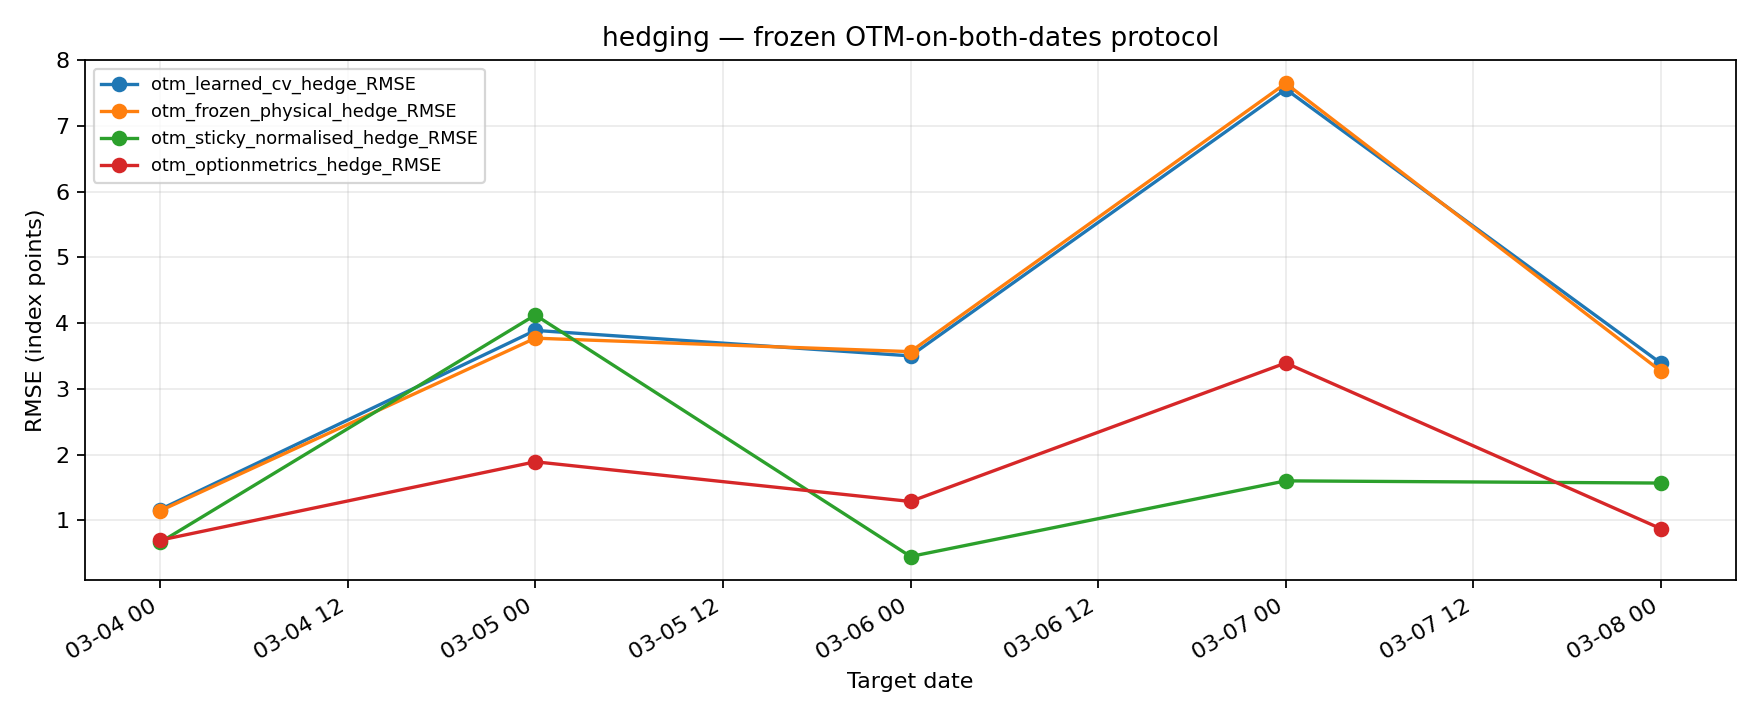

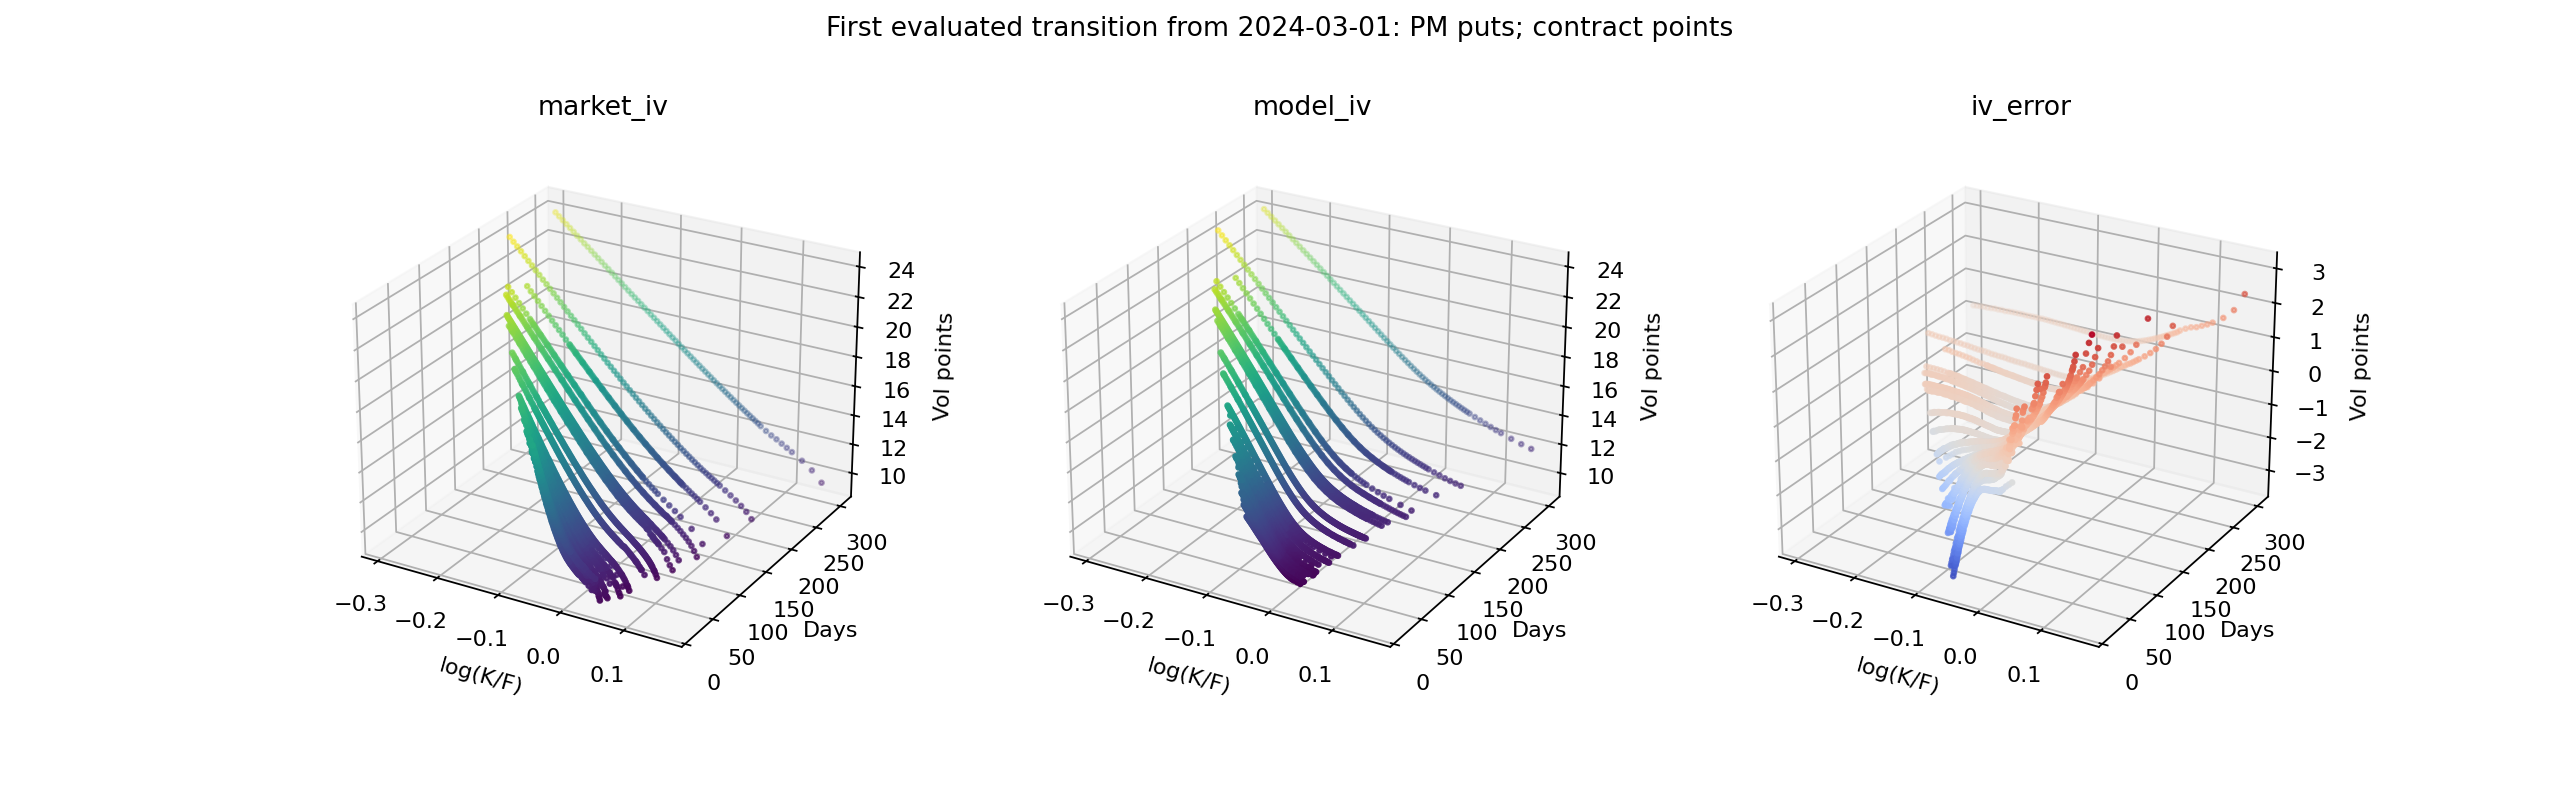

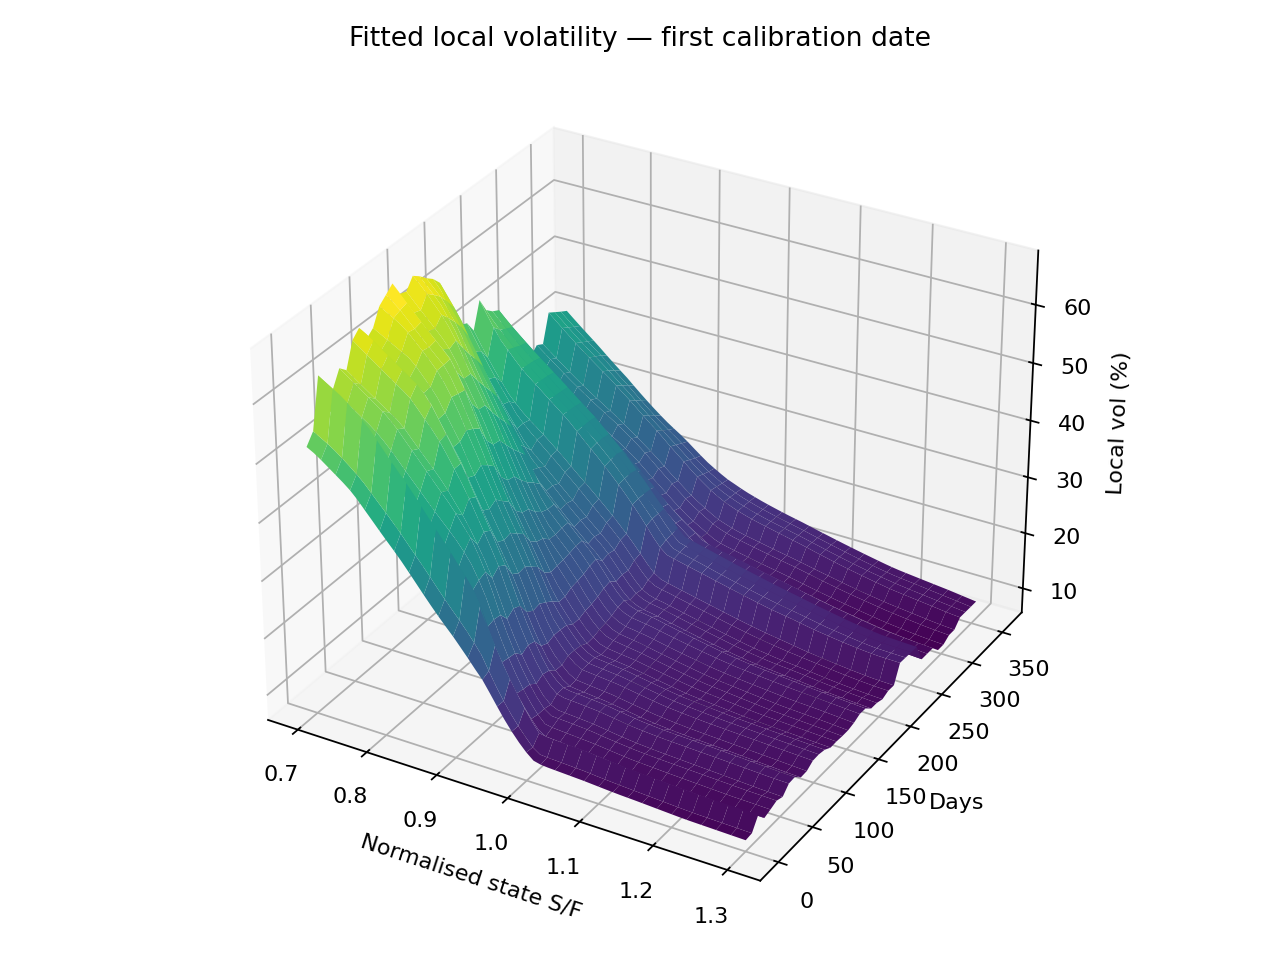

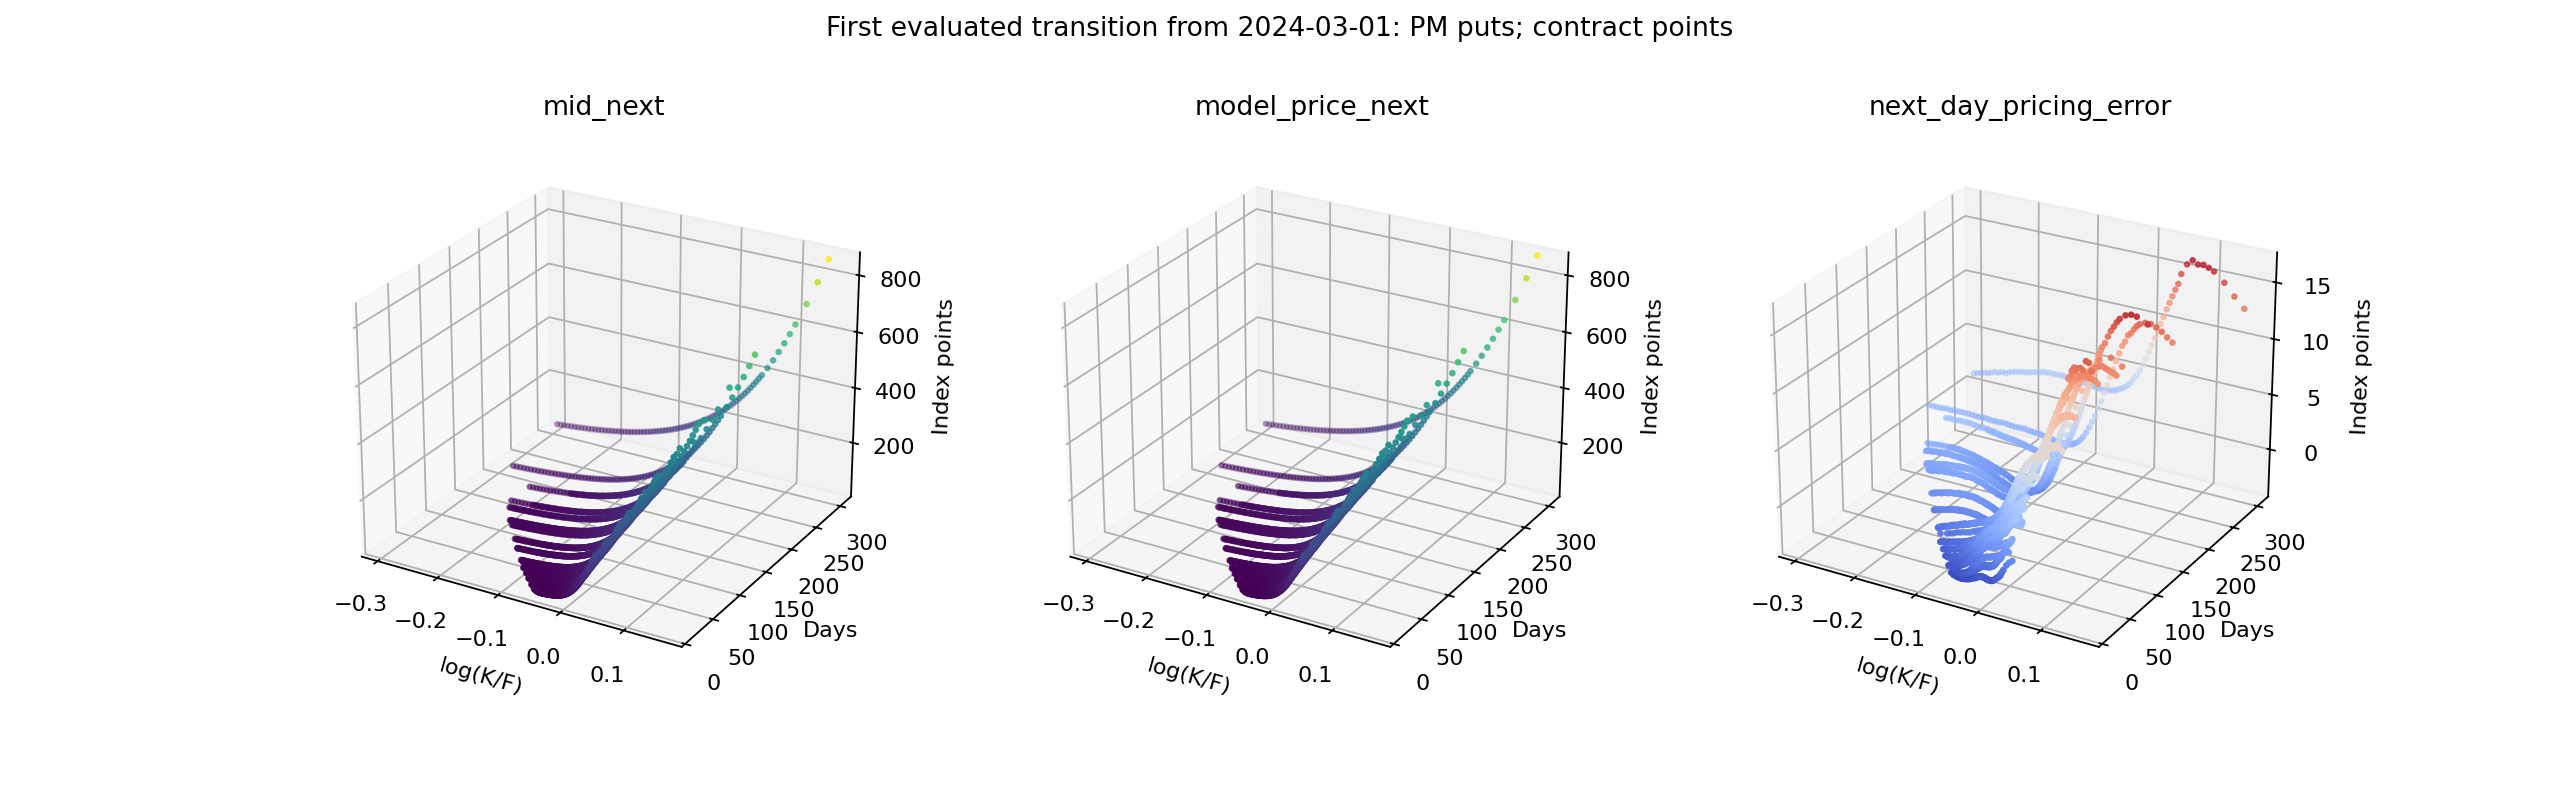

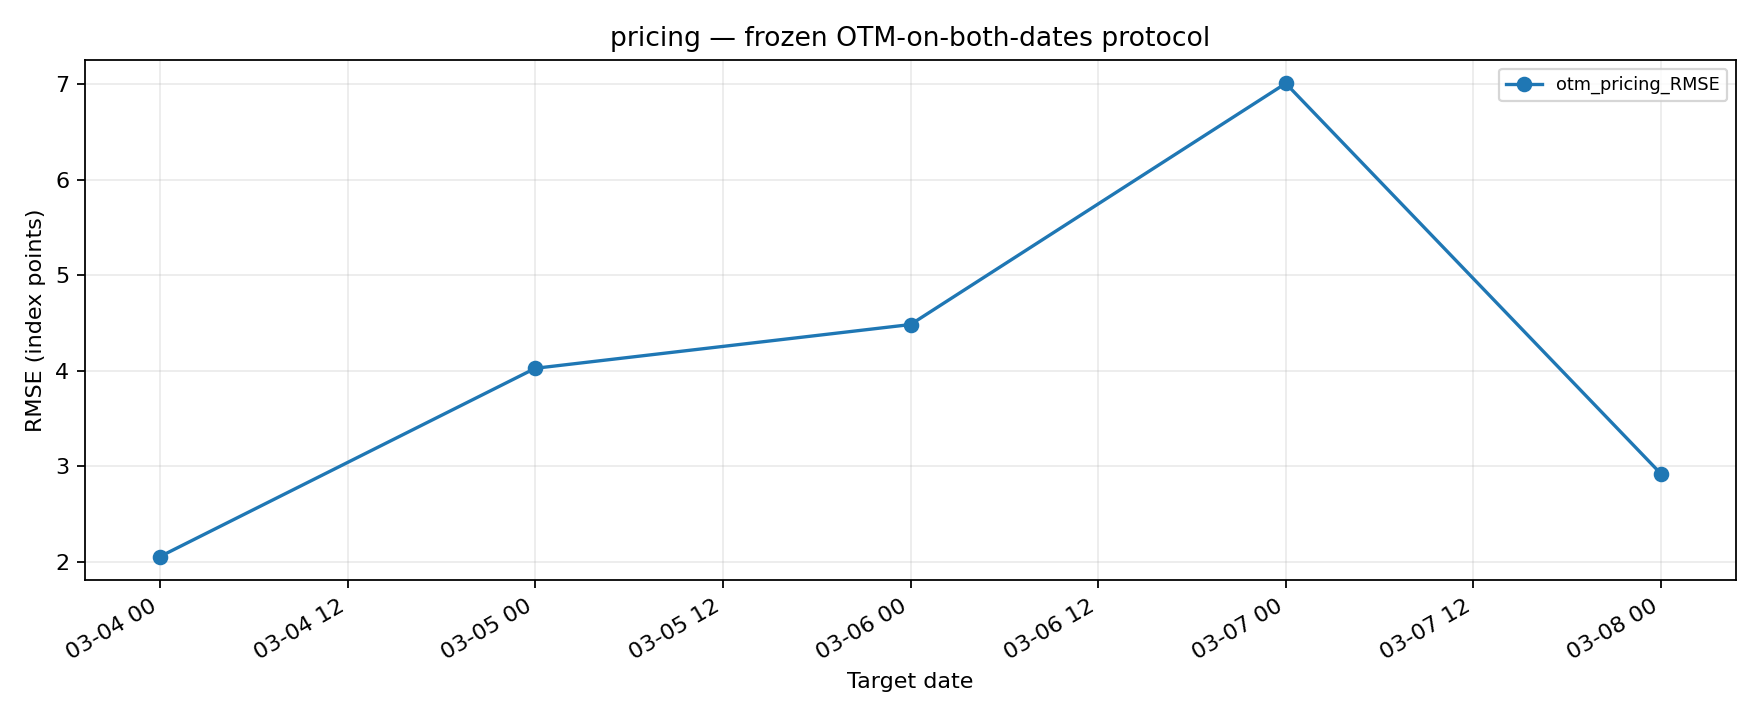

In [44]:
PLOT_SCRIPT = r"""
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

root = Path(sys.argv[1])
report = root / 'reports'
plots = root / 'plots'
plots.mkdir(exist_ok=True)
daily = pd.read_csv(root / 'daily_summary.csv', parse_dates=['next_date'])
plot_sets = [
    ('pricing', ['otm_pricing_RMSE']),
    ('hedging', [
        'otm_learned_cv_hedge_RMSE', 'otm_frozen_physical_hedge_RMSE',
        'otm_sticky_normalised_hedge_RMSE', 'otm_optionmetrics_hedge_RMSE',
    ]),
]
for name, columns in plot_sets:
    fig, axis = plt.subplots(figsize=(11, 4.5))
    for column in columns:
        if column in daily:
            axis.plot(daily.next_date, daily[column], marker='o', label=column)
    axis.set(title=name + ' — frozen OTM-on-both-dates protocol',
             xlabel='Target date', ylabel='RMSE (index points)')
    axis.legend(fontsize=8)
    axis.grid(alpha=0.25)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(plots / (name + '.png'), dpi=160)
    plt.close(fig)

contracts = pd.read_csv(report / 'diagnostic_contracts.csv', low_memory=False)
date = contracts.date.iloc[0]
surface = contracts.loc[
    contracts.date.eq(date) & contracts.cp_flag.eq('P') & contracts.am_settlement.eq(0)
].copy()
surface['days'] = 365 * surface.T_next
for label, columns, scale in [
    ('price', ['mid_next', 'model_price_next', 'next_day_pricing_error'], 1),
    ('iv', ['market_iv', 'model_iv', 'iv_error'], 100),
]:
    group = surface.dropna(subset=columns)
    if group.empty:
        continue
    figure = plt.figure(figsize=(16, 5))
    low, high = group[columns[:2]].min().min() * scale, group[columns[:2]].max().max() * scale
    for i, column in enumerate(columns, 1):
        axis = figure.add_subplot(1, 3, i, projection='3d')
        z = group[column] * scale
        axis.scatter(group.k_next, group.days, z, c=z,
                     cmap='viridis' if i < 3 else 'coolwarm', s=4)
        axis.set(xlabel='log(K/F)', ylabel='Days',
                 zlabel='Index points' if label == 'price' else 'Vol points', title=column)
        if i < 3 and high > low:
            axis.set_zlim(low, high)
        axis.view_init(25, -60)
    figure.suptitle(f'First evaluated transition from {date}: PM puts; contract points')
    figure.subplots_adjust(wspace=0.25, bottom=0.12, top=0.85)
    figure.savefig(plots / (label + '_surface.png'), dpi=160)
    plt.close(figure)

meshes = sorted(root.glob('eval_*/*_local_vol_mesh.csv'))
if meshes:
    mesh = pd.read_csv(meshes[0])
    pivot = mesh.pivot(index='t', columns='x', values='sigma')
    x, t = np.meshgrid(pivot.columns.to_numpy(), 365 * pivot.index.to_numpy())
    figure = plt.figure(figsize=(8, 6))
    axis = figure.add_subplot(111, projection='3d')
    axis.plot_surface(x, t, 100 * pivot.to_numpy(), cmap='viridis', linewidth=0)
    axis.set(xlabel='Normalised state S/F', ylabel='Days', zlabel='Local vol (%)',
             title='Fitted local volatility — first calibration date')
    figure.tight_layout()
    figure.savefig(plots / 'local_vol_surface.png', dpi=160)
    plt.close(figure)
print('Plots saved to', plots)
"""

from IPython.display import Image, display

for item in RESULTS:
    environment = os.environ.copy()
    environment.pop('KMP_DUPLICATE_LIB_OK', None)
    environment['MPLBACKEND'] = 'Agg'
    child = subprocess.run(
        [sys.executable, '-X', 'faulthandler', '-c', PLOT_SCRIPT, item['folder']],
        env=environment, capture_output=True, text=True,
    )
    (Path(item['folder']) / 'plot_process.log').write_text(
        child.stdout + '\n' + child.stderr, encoding='utf-8'
    )
    if child.returncode:
        print('Plot process failed; numerical files intact:', item['folder'], child.stderr[-1500:])
    else:
        print(child.stdout)
        for path in sorted((Path(item['folder']) / 'plots').glob('*.png')):
            display(Image(filename=str(path)))


## Completion checklist

- The old 4k/8k caches are legacy diagnostics; corrected runs use a new namespace and hashes.
- Research modes require CUDA and the exact CPU anchor; CPU fallback is smoke-only.
- The rolling teacher maps both calendar time and forward-normalised state.
- Temporal regularisation and optional CV transfer use that mapped function, not parameter distance.
- The CPU coefficient anchor is unchanged; a resumable CV-only stage supplies its learned hedge.
- Learned-CV, frozen-physical, sticky-normalised and OptionMetrics deltas remain separate throughout.
- Every delta uses the identical overnight discount/dividend/cash convention.
- Bounded selection includes update zero and uses date-$t$ information only.
- Huber and replay derivatives follow the notebook's $r^2$ MSE convention.
- Numerical-grid audits aggregate identical finest-grid Brownian increments.
- Contract CSVs precede summaries/plots and contain raw residuals, carry components, MC price SEs,
  seeds, hashes, OTM flags, maturity and moneyness.
- Development comparison reports a Pareto frontier; it does not select a best seed or optimize an
  undisclosed scalar score.
- March 8–28 is observed. Only genuinely later data can provide an untouched test.

### Validation performed before delivery

Every code cell is statically compiled. All named configurations are constructed and validated.
Static invariants check the new cache namespace, causal checkpoint label, curve-aware state mapping,
learned-CV output, common hedge-accounting function, coupled-grid audit, complete resume state and
the absence of a launchable 40k/500-update configuration. The CPU-checkpoint loader retains clear
missing/incompatible-path errors. Full CUDA calibration is intentionally not started during build;
the mandatory runtime audits execute before the experiment cell on the target environment.
